# A guide Portfolio Optimization Environment

This notebook aims to provide an example of using PortfolioOptimizationEnv (or POE) to train a reinforcement learning model that learns to solve the portfolio optimization problem.

In this document, we will reproduce a famous architecture called EI3 (ensemble of identical independent evaluators), introduced in the following paper:

- Zhengyao Jiang, Dixing Xu, & Jinjun Liang. (2017). A Deep Reinforcement Learning Framework for the Financial Portfolio Management Problem. https://doi.org/10.48550/arXiv.1706.10059.

It's advisable to read it to understand the algorithm implemented in this notebook.

### Note
If you're using this environment, consider citing the following paper (in adittion to FinRL references):

- Caio Costa, & Anna Costa (2023). POE: A General Portfolio Optimization Environment for FinRL. In *Anais do II Brazilian Workshop on Artificial Intelligence in Finance* (pp. 132–143). SBC. https://doi.org/10.5753/bwaif.2023.231144.

```
@inproceedings{bwaif,
 author = {Caio Costa and Anna Costa},
 title = {POE: A General Portfolio Optimization Environment for FinRL},
 booktitle = {Anais do II Brazilian Workshop on Artificial Intelligence in Finance},
 location = {João Pessoa/PB},
 year = {2023},
 keywords = {},
 issn = {0000-0000},
 pages = {132--143},
 publisher = {SBC},
 address = {Porto Alegre, RS, Brasil},
 doi = {10.5753/bwaif.2023.231144},
 url = {https://sol.sbc.org.br/index.php/bwaif/article/view/24959}
}

```

## Installation and imports

To run this notebook in google colab, uncomment the cells below.

In [1]:
## Hide matplotlib warnings
# import warnings
# warnings.filterwarnings('ignore')

import logging
logging.getLogger('matplotlib.font_manager').disabled = True

#### Import the necessary code libraries

In [ ]:
import torch

from sklearn.preprocessing import MaxAbsScaler
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import random
import numpy as np
from finrl.meta.preprocessor.yahoodownloader import YahooDownloader
from finrl.meta.preprocessor.preprocessors import GroupByScaler
from finrl.meta.env_portfolio_optimization.env_portfolio_optimization import PortfolioOptimizationEnv
from finrl.agents.portfolio_optimization.models_raw import DRLAgent
from finrl.agents.portfolio_optimization.architectures_raw import GPM

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,
})

TNR_FONT = FontProperties(family="Times New Roman")
SONGTI_FONT = FontProperties(family="SimSun")

def has_chinese(text):
    text = str(text)
    return any("一" <= ch <= "鿿" for ch in text)

def choose_font(text):
    return SONGTI_FONT if has_chinese(text) else TNR_FONT

def apply_font_to_text(text_obj):
    if text_obj is None:
        return
    text_obj.set_fontproperties(choose_font(text_obj.get_text()))

def apply_times_new_roman(ax):
    apply_font_to_text(ax.title)
    apply_font_to_text(ax.xaxis.label)
    apply_font_to_text(ax.yaxis.label)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        apply_font_to_text(label)
    legend = ax.get_legend()
    if legend is not None:
        for text in legend.get_texts():
            apply_font_to_text(text)
        if legend.get_title() is not None:
            apply_font_to_text(legend.get_title())

def apply_times_new_roman_to_legend(legend):
    if legend is not None:
        for text in legend.get_texts():
            apply_font_to_text(text)
        if legend.get_title() is not None:
            apply_font_to_text(legend.get_title())

SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

device = 'cuda:0' if torch.cuda.is_available() else 'cpu'

## Fetch data

In his paper, *Jiang et al* creates a portfolio composed by the top-11 cryptocurrencies based on 30-days volume. Since it's not specified when this classification was done, it's difficult to reproduce, so we will use a similar approach in the Brazillian stock market:

- We select top-10 stocks from Brazillian stock market;
- For simplicity, we disconsider stocks that have missing data for the days in period 2011-01-01 to 2019-12-31 (9 years);

In [3]:
TOP_BRL = [
        "601012.SS",
        "600887.SS",
        "600030.SS",   
        "600031.SS",
        "600036.SS",        
        "600276.SS", 
        "600519.SS", 
        "601318.SS", 
        "600703.SS", 
        "601166.SS", 
    ]

In [4]:
%env HTTP_PROXY=http://127.0.0.1:7897
%env HTTPS_PROXY=http://127.0.0.1:7897

env: HTTP_PROXY=http://127.0.0.1:7897
env: HTTPS_PROXY=http://127.0.0.1:7897


In [5]:
print(len(TOP_BRL))

portfolio_raw_df = YahooDownloader(start_date = '2014-01-01',
                                end_date = '2025-12-31',
                                ticker_list = TOP_BRL).fetch_data()
portfolio_raw_df

10


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Shape of DataFrame:  (29160, 8)


Price,date,close,high,low,open,volume,tic,day
0,2014-01-02,9.274567,9.348232,9.193533,9.289300,71936303,600030.SS,3
1,2014-01-02,5.264814,5.289570,5.248310,5.289570,9087799,600031.SS,3
2,2014-01-02,6.447871,6.525990,6.411816,6.513972,53256490,600036.SS,3
3,2014-01-02,8.174829,8.308774,7.932054,7.950889,36239316,600276.SS,3
4,2014-01-02,80.822762,82.112281,80.578972,82.112281,2659175,600519.SS,3
...,...,...,...,...,...,...,...,...
29155,2025-12-30,14.160000,14.420000,14.100000,14.320000,74844398,600703.SS,1
29156,2025-12-30,28.690001,28.900000,28.610001,28.760000,39049803,600887.SS,1
29157,2025-12-30,18.440001,18.750000,18.400000,18.549999,98250988,601012.SS,1
29158,2025-12-30,20.475147,20.795526,20.455730,20.727567,67534398,601166.SS,1


In [6]:
portfolio_raw_df.groupby("tic").count()

Price,date,close,high,low,open,volume,day
tic,,,,,,,
600030.SS,2916,2916,2916,2916,2916,2916,2916
600031.SS,2916,2916,2916,2916,2916,2916,2916
600036.SS,2916,2916,2916,2916,2916,2916,2916
600276.SS,2916,2916,2916,2916,2916,2916,2916
600519.SS,2916,2916,2916,2916,2916,2916,2916
600703.SS,2916,2916,2916,2916,2916,2916,2916
600887.SS,2916,2916,2916,2916,2916,2916,2916
601012.SS,2916,2916,2916,2916,2916,2916,2916
601166.SS,2916,2916,2916,2916,2916,2916,2916


### Normalize Data

We normalize the data dividing the time series of each stock by its maximum value, so that the dataframe contains values between 0 and 1.

In [7]:
portfolio_norm_df = GroupByScaler(by="tic", scaler=MaxAbsScaler).fit_transform(portfolio_raw_df)
portfolio_norm_df

c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.04898638 0.06069891 0.07574341 ... 0.0962567  0.06174419 0.05817843]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(
c:\Users\64954\Desktop\material\vscode\FinRL\finrl\meta\preprocessor\preprocessors.py:100: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.75 1.   0.   ... 1.   0.   0.25]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  X.loc[select_mask, self.columns] = self.scalers[value].transform(


Price,date,close,high,low,open,volume,tic,day
0,2014-01-02,0.273184,0.263205,0.273384,0.261546,0.048986,600030.SS,0.75
1,2014-01-02,0.122140,0.116932,0.124431,0.118178,0.010523,600031.SS,0.75
2,2014-01-02,0.141247,0.141939,0.142627,0.143405,0.056458,600036.SS,0.75
3,2014-01-02,0.086874,0.086892,0.086443,0.083838,0.186574,600276.SS,0.75
4,2014-01-02,0.035453,0.035650,0.036996,0.036199,0.083608,600519.SS,0.75
...,...,...,...,...,...,...,...,...
29155,2025-12-30,0.318843,0.324698,0.332674,0.326885,0.178415,600703.SS,0.25
29156,2025-12-30,0.666377,0.669184,0.694480,0.670468,0.071503,600887.SS,0.25
29157,2025-12-30,0.265548,0.261909,0.268890,0.267666,0.099014,601012.SS,0.25
29158,2025-12-30,0.838902,0.841650,0.844828,0.849582,0.049759,601166.SS,0.25


In [8]:
df_portfolio = portfolio_norm_df[["date", "tic", "close", "high", "low"]]

# 训练集：2014-2021
df_portfolio_train = df_portfolio[
    (df_portfolio["date"] >= "2014-01-01") & 
    (df_portfolio["date"] < "2022-01-01")
]

# 验证集：2022全年（从训练集末尾切出来）
df_portfolio_val = df_portfolio[
    (df_portfolio["date"] >= "2022-01-01") & 
    (df_portfolio["date"] < "2023-01-01")
]

# 测试集：2023-2025全年
df_portfolio_2023 = df_portfolio[
    (df_portfolio["date"] >= "2023-01-01") & 
    (df_portfolio["date"] < "2024-01-01")
]

df_portfolio_2024 = df_portfolio[
    (df_portfolio["date"] >= "2024-01-01") & 
    (df_portfolio["date"] < "2025-01-01")
]

df_portfolio_2025 = df_portfolio[
    (df_portfolio["date"] >= "2025-01-01") & 
    (df_portfolio["date"] < "2026-01-01")
]

### Instantiate Environment

Using the `PortfolioOptimizationEnv`, it's easy to instantiate a portfolio optimization environment for reinforcement learning agents. In the example below, we use the dataframe created before to start an environment.

In [9]:
environment = PortfolioOptimizationEnv(
        df_portfolio_train,
        initial_amount=100000,
        comission_fee_pct=0.0020,
        time_window=50,
        features=["close", "high", "low"],
        normalize_df=None
    )

# 验证集环境（参数与训练环境保持一致）
environment_val = PortfolioOptimizationEnv(
        df_portfolio_val,
        initial_amount=100000,
        comission_fee_pct=0.0020,
        time_window=50,
        features=["close", "high", "low"],
        normalize_df=None
)


### Instantiate Model

Now, we can instantiate the model using FinRL API. In this example, we are going to use the EI3 architecture introduced by Jiang et. al.

:exclamation: **Note:** Remember to set the architecture's `time_window` parameter with the same value of the environment's `time_window`.

In [10]:
import numpy as np
import torch

# 你的股票列表（按排序后的顺序）
TICKERS = sorted(TOP_BRL)  # 确保顺序和环境里一致
N = len(TICKERS)           # 10只股票，节点0-9

# ── nodes_to_select ──────────────────────────────────────
# 选择哪些节点进入组合，这里全选
nodes_to_select = list(range(N))  # [0,1,2,...,9]

# ── edge_index：定义股票之间的连接关系 ───────────────────
# GPM论文里用的是全连接图（每只股票和其他所有股票都有边）
# 排除自环
sources, targets, types = [], [], []

for i in range(N):
    for j in range(N):
        if i != j:
            sources.append(i)
            targets.append(j)
            types.append(0)  # 先全用同一种关系类型

edge_index = np.array([sources, targets])  # shape [2, N*(N-1)]
edge_type  = np.array(types)               # shape [N*(N-1)]

print(f"节点数: {N}")
print(f"边数: {edge_index.shape[1]}")  # 应该是 10*9=90
print(f"关系类型数: {np.unique(edge_type)}")

节点数: 10
边数: 90
关系类型数: [0]


In [51]:
# set PolicyGradient parameters
model_kwargs = {
    "lr": 0.001,
    "policy": GPM,
}

# here, we can set GPM's parameters
policy_kwargs = {
        "edge_index": edge_index,
        "edge_type": edge_type,
        "nodes_to_select": nodes_to_select,
        "initial_features": 3,
        "k_short": 3,
        "k_medium": 21,
        "conv_mid_features": 3,
        "conv_final_features": 20,
        "graph_layers": 1,
        "time_window": 50,
        "softmax_temperature": 1,
}

model = DRLAgent(environment).get_model("pg", device, model_kwargs, policy_kwargs)

### Train Model

In [52]:
import torch
import numpy as np
import matplotlib.pyplot as plt

import numpy as np
import copy

def calculate_sharpe(value_list, risk_free_rate=0, periods_per_year=252):
    """从组合净值序列计算年化 Sharpe Ratio（无风险利率默认2%）"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    if daily_returns.std() == 0:
        return 0.0
    excess = daily_returns.mean() - risk_free_rate / periods_per_year
    return (excess / daily_returns.std()) * np.sqrt(periods_per_year)

def calculate_metrics(value_list, risk_free_rate=0, periods_per_year=252):
    """计算完整指标：累计收益、年化收益、波动率、Sharpe、最大回撤、Calmar"""
    values = np.array(value_list)
    daily_returns = np.diff(values) / values[:-1]
    
    total_return   = (values[-1] / values[0]) - 1
    n_days         = len(values) - 1
    annual_return  = (1 + total_return) ** (periods_per_year / n_days) - 1
    annual_vol     = daily_returns.std() * np.sqrt(periods_per_year)
    
    excess         = daily_returns.mean() - risk_free_rate / periods_per_year
    sharpe         = (excess / daily_returns.std()) * np.sqrt(periods_per_year) if daily_returns.std() != 0 else 0.0
    
    cumulative     = values / values[0]
    rolling_max    = np.maximum.accumulate(cumulative)
    drawdown       = (cumulative - rolling_max) / rolling_max
    max_drawdown   = drawdown.min()
    calmar         = annual_return / abs(max_drawdown) if max_drawdown != 0 else 0.0
    
    return {
        "累计收益":   round(total_return,  4),
        "年化收益":   round(annual_return, 4),
        "年化波动率": round(annual_vol,    4),
        "Sharpe":    round(sharpe,        4),
        "最大回撤":   round(max_drawdown,  4),
        "Calmar":    round(calmar,        4),
    }

# ── Early Stop 配置 ──────────────────────────────────────
MAX_EPISODES   = 20    # 最大训练轮数（可根据算力调整）
PATIENCE       = 3     # 连续多少轮验证集无改善则停止
SAVE_PATH      = "policy_GPM_best.pt"

# ── 训练状态 ─────────────────────────────────────────────
best_val_sharpe  = -np.inf
best_episode     = 0
patience_counter = 0
history = {"val_sharpe": [], "val_return": []}

print(f"开始训练，最大轮数={MAX_EPISODES}，早停耐心值={PATIENCE}")
print("-" * 60)

for episode in range(1, MAX_EPISODES + 1):

    # 1. 训练一个 episode
    DRLAgent.train_model(model, episodes=1)

    # 2. 在验证集上评估
    DRLAgent.DRL_validation(model, environment_val, policy=model.train_policy)
    val_values = environment_val._asset_memory["final"]

    val_sharpe = calculate_sharpe(val_values)
    val_return = (val_values[-1] / val_values[0]) - 1
    history["val_sharpe"].append(val_sharpe)
    history["val_return"].append(val_return)

    print(f"第{episode:3d}轮 | 验证集 Sharpe: {val_sharpe:+.4f} | "
          f"验证集收益: {val_return:+.4f} | 历史最优: {best_val_sharpe:+.4f}（第{best_episode}轮）")

    # 3. 保存最优 checkpoint
    if val_sharpe > best_val_sharpe:
        best_val_sharpe  = val_sharpe
        best_episode     = episode
        patience_counter = 0
        torch.save(model.train_policy.state_dict(), SAVE_PATH)
        print(f"  ✓ 验证集 Sharpe 创新高，已保存最优模型 → {SAVE_PATH}")
    else:
        patience_counter += 1
        print(f"  耐心计数：{patience_counter}/{PATIENCE}")

    # 4. Early stopping
    if patience_counter >= PATIENCE:
        print(f"早停触发（第{episode}轮）")
        print(f"   最优轮次：第{best_episode}轮 | 验证集 Sharpe：{best_val_sharpe:.4f}")
        break

print("训练结束，加载最优权重...")
policy = GPM(
    edge_index,
    edge_type,
    nodes_to_select,
    device=device
)
policy.load_state_dict(torch.load(SAVE_PATH))
print(f"已加载最优模型（来自第{best_episode}轮，验证集 Sharpe = {best_val_sharpe:.4f}）")



开始训练，最大轮数=20，早停耐心值=3
------------------------------------------------------------


  0%|          | 0/1 [00:00<?, ?it/s]

Initial portfolio value:100000
Final portfolio value: 732628.25
Final accumulative portfolio value: 7.3262825
Maximum DrawDown: -0.36833178739587813
Sharpe ratio: 1.2646096869268284


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)
100%|██████████| 1/1 [00:45<00:00, 45.50s/it]


Initial portfolio value:100000
Final portfolio value: 92997.3046875
Final accumulative portfolio value: 0.929973046875
Maximum DrawDown: -0.2217206152734974
Sharpe ratio: -0.3487433707846657


...

c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)
100%|██████████| 1/1 [01:15<00:00, 75.08s/it]


Initial portfolio value:100000
Final portfolio value: 103526.25
Final accumulative portfolio value: 1.0352625
Maximum DrawDown: -0.2607323972435749
Sharpe ratio: 0.30642307611731257


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


第 12轮 | 验证集 Sharpe: +0.3080 | 验证集收益: +0.0353 | 历史最优: +0.3123（第9轮）
  耐心计数：3/3
早停触发（第12轮）
   最优轮次：第9轮 | 验证集 Sharpe：0.3123
训练结束，加载最优权重...
已加载最优模型（来自第9轮，验证集 Sharpe = 0.3123）


C:\Users\64954\AppData\Local\Temp\ipykernel_57696\1839769572.py:100: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load(SAVE_PATH))


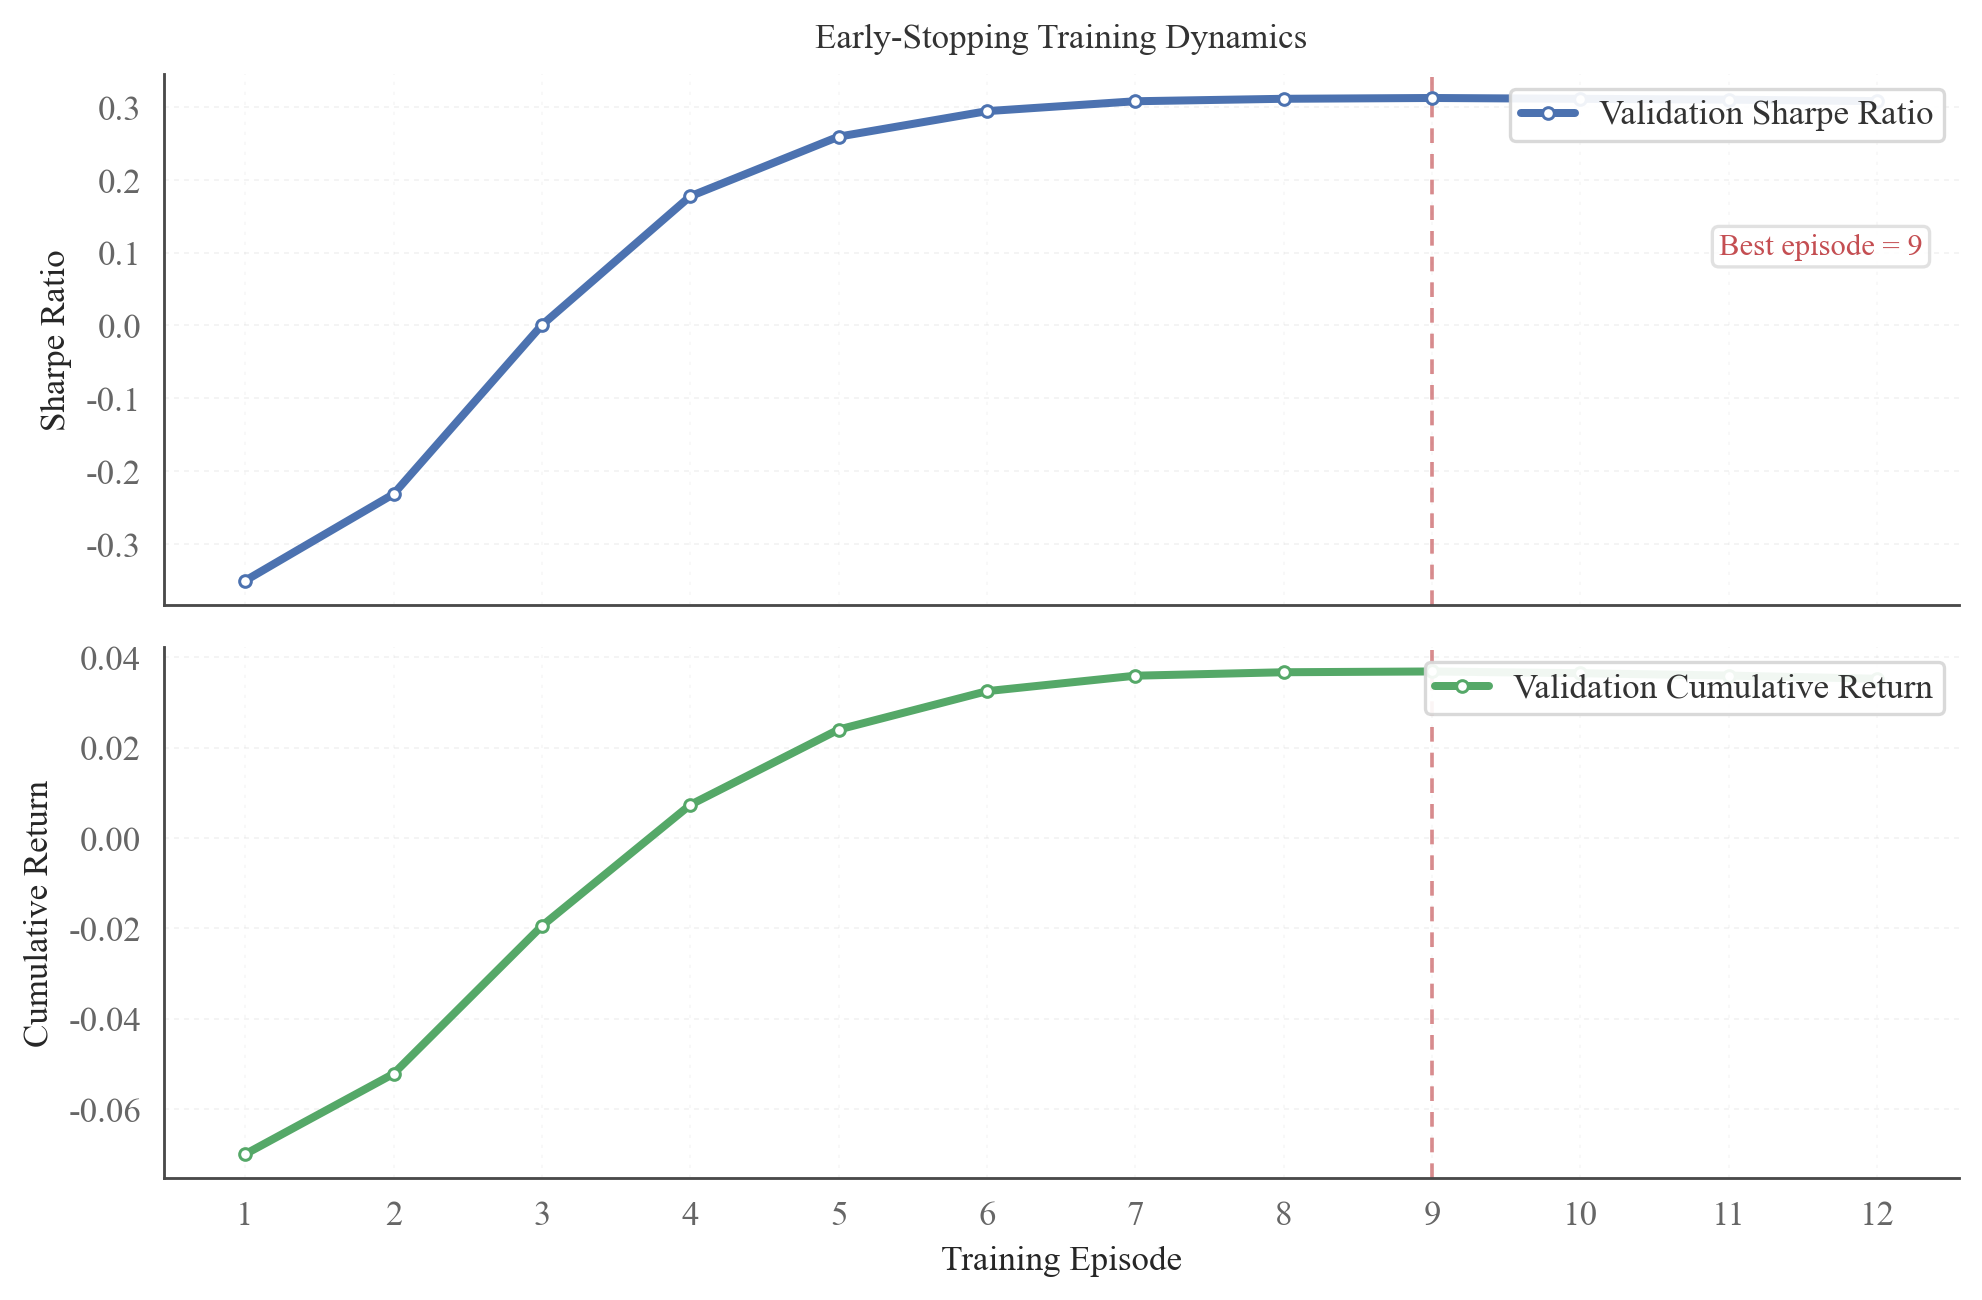

Training curves saved to: raw_GPM_sse50_figures\training_curve.png


In [53]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import os

output_dir = "raw_GPM_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 10.5,
    "axes.labelsize": 11.5,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,

    "axes.linewidth": 0.85,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.18,
    "lines.linewidth": 2.4,
})

COLOR_SHARPE = "#4C72B0"
COLOR_RETURN = "#55A868"
COLOR_BEST = "#C44E52"
GRID_COLOR = "#B8B8B8"
SPINE_COLOR = "#4A4A4A"

episodes = np.arange(1, len(history["val_sharpe"]) + 1)
best_x = best_episode

fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(8.8, 5.9),
    sharex=True,
    gridspec_kw={"hspace": 0.08}
)

# Top panel: validation Sharpe ratio
ax1.plot(
    episodes,
    history["val_sharpe"],
    color=COLOR_SHARPE,
    marker="o",
    markersize=3.5,
    markerfacecolor="white",
    markeredgewidth=0.9,
    label="Validation Sharpe Ratio",
    zorder=3
)
ax1.axvline(
    best_x,
    color=COLOR_BEST,
    linestyle=(0, (4, 3)),
    linewidth=1.1,
    alpha=0.65,
    zorder=2
)
ax1.set_ylabel("Sharpe Ratio")
ax1.set_title("Early-Stopping Training Dynamics", pad=8)

ax1.grid(True, axis="y", linestyle=(0, (3, 3)), color=GRID_COLOR)
ax1.grid(True, axis="x", linestyle=(0, (2, 4)), color=GRID_COLOR, alpha=0.10)
ax1.set_axisbelow(True)

ax1.legend(
    loc="upper right",
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#D6D6D6",
    borderpad=0.35,
    handlelength=1.8
)

ax1.text(
    0.98, 0.7,
    f"Best episode = {best_episode}",
    transform=ax1.transAxes,
    ha="right",
    va="top",
    fontsize=9.2,
    color=COLOR_BEST,
    bbox=dict(
        boxstyle="round,pad=0.22",
        facecolor="white",
        edgecolor="#DDDDDD",
        alpha=0.88
    )
)

# Bottom panel: validation cumulative return
ax2.plot(
    episodes,
    history["val_return"],
    color=COLOR_RETURN,
    marker="o",
    markersize=3.5,
    markerfacecolor="white",
    markeredgewidth=0.9,
    label="Validation Cumulative Return",
    zorder=3
)
ax2.axvline(
    best_x,
    color=COLOR_BEST,
    linestyle=(0, (4, 3)),
    linewidth=1.1,
    alpha=0.65,
    zorder=2
)
ax2.set_ylabel("Cumulative Return")
ax2.set_xlabel("Training Episode")

ax2.grid(True, axis="y", linestyle=(0, (3, 3)), color=GRID_COLOR)
ax2.grid(True, axis="x", linestyle=(0, (2, 4)), color=GRID_COLOR, alpha=0.10)
ax2.set_axisbelow(True)

ax2.legend(
    loc="upper right",
    frameon=True,
    framealpha=0.92,
    facecolor="white",
    edgecolor="#D6D6D6",
    borderpad=0.35,
    handlelength=1.8
)

# Integer episode ticks
ax2.set_xticks(episodes)

# Spine and tick styling
for ax in (ax1, ax2):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(SPINE_COLOR)
    ax.spines["bottom"].set_color(SPINE_COLOR)
    ax.tick_params(
        axis="both",
        which="major",
        length=3.2,
        width=0.75,
        color=SPINE_COLOR
    )
    apply_times_new_roman(ax)

fig.subplots_adjust(
    left=0.12,
    right=0.97,
    top=0.90,
    bottom=0.12,
    hspace=0.08
)

png_path = os.path.join(output_dir, "training_curve.png")
fig.savefig(png_path, bbox_inches="tight")

plt.show()
print("Training curves saved to:", png_path)


## Test Model

### Instantiate different environments

Since we have three different periods of time, we need three different environments instantiated to simulate them.

In [54]:
environment_2023 = PortfolioOptimizationEnv(
    df_portfolio_2023,
    initial_amount=100000,
    comission_fee_pct=0.002,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

environment_2024 = PortfolioOptimizationEnv(
    df_portfolio_2024,
    initial_amount=100000,
    comission_fee_pct=0.002,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

environment_2025 = PortfolioOptimizationEnv(
    df_portfolio_2025,
    initial_amount=100000,
    comission_fee_pct=0.002,
    time_window=50,
    features=["close", "high", "low"],
    normalize_df=None
)

### Test EI3 architecture
Now, we can test the EI3 architecture in the three different test periods. It's important no note that, in this code, we load the saved policy even though it's not necessary just to show how to save and load your model.

In [55]:
import numpy as np

GPM_results = {
    "training": environment._asset_memory["final"],
    "validation": {"value": list(environment_val._asset_memory["final"])},
    "2023": {},
    "2024": {},
    "2025": {}
}

# instantiate an architecture with the same arguments used in training
# and load with load_state_dict.
policy = GPM(
    edge_index,
    edge_type,
    nodes_to_select,
    device=device
)
policy.load_state_dict(torch.load("policy_GPM_best.pt"))

DRLAgent.DRL_validation(model, environment_val, policy=policy)
GPM_results["validation"] = {
    "value": list(environment_val._asset_memory["final"])
}

for year, env in [("2023", environment_2023),
                  ("2024", environment_2024),
                  ("2025", environment_2025)]:
    DRLAgent.DRL_validation(model, env, policy=policy)
    values = env._asset_memory["final"]
    actions = np.array(env._actions_memory).copy()
    turnover = np.sum(np.abs(np.diff(actions[:, 1:], axis=0)), axis=1)
    GPM_results[year] = {
        "value":   list(values),
        "actions": actions,
        "turnover": turnover
    }

C:\Users\64954\AppData\Local\Temp\ipykernel_57696\2696176245.py:19: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  policy.load_state_dict(torch.load("policy_GPM_best.pt"))


Initial portfolio value:100000
Final portfolio value: 103687.984375
Final accumulative portfolio value: 1.03687984375
Maximum DrawDown: -0.25626880823576403
Sharpe ratio: 0.3107098376582646


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 82546.171875
Final accumulative portfolio value: 0.82546171875
Maximum DrawDown: -0.27112727665913783
Sharpe ratio: -0.9788874649174557


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 89075.9921875
Final accumulative portfolio value: 0.890759921875
Maximum DrawDown: -0.28334539062499997
Sharpe ratio: -0.17257298997393428


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 111452.046875
Final accumulative portfolio value: 1.11452046875
Maximum DrawDown: -0.20641269489518144
Sharpe ratio: 0.5861711456520723


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


### Test Uniform Buy and Hold
For comparison, we will also test the performance of a uniform buy and hold strategy. In this strategy, the portfolio has no remaining cash and the same percentage of money is allocated in each asset.

In [56]:
EW_results = {
    "train": {},
    "validation": {},
    "2023": {},
    "2024": {},
    "2025": {}
}

PORTFOLIO_SIZE = len(TOP_BRL)

# train period
terminated = False
environment.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment.step(action)
EW_results["train"]["value"] = environment._asset_memory["final"]

# validation period
terminated = False
environment_val.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_val.step(action)
EW_results["validation"]["value"] = environment_val._asset_memory["final"]

# 2023
terminated = False
environment_2023.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2023.step(action)
EW_results["2023"]["value"] = environment_2023._asset_memory["final"]

# 2024
terminated = False
environment_2024.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2024.step(action)
EW_results["2024"]["value"] = environment_2024._asset_memory["final"]

# 2025
terminated = False
environment_2025.reset()
while not terminated:
    action = [0] + [1/PORTFOLIO_SIZE] * PORTFOLIO_SIZE
    _, _, terminated, _ = environment_2025.step(action)
EW_results["2025"]["value"] = environment_2025._asset_memory["final"]

Initial portfolio value:100000
Final portfolio value: 816537.375
Final accumulative portfolio value: 8.16537375
Maximum DrawDown: -0.39472304670502634
Sharpe ratio: 1.242334828100936


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 91639.140625
Final accumulative portfolio value: 0.91639140625
Maximum DrawDown: -0.24650649697059268
Sharpe ratio: -0.3853091164118296


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 90655.546875
Final accumulative portfolio value: 0.90655546875
Maximum DrawDown: -0.18683311913998157
Sharpe ratio: -0.7532256096690312


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 112132.1875
Final accumulative portfolio value: 1.121321875
Maximum DrawDown: -0.12743942382549034
Sharpe ratio: 0.7484854467740468


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


Initial portfolio value:100000
Final portfolio value: 110016.9921875
Final accumulative portfolio value: 1.100169921875
Maximum DrawDown: -0.08930796875000002
Sharpe ratio: 0.9741955718855567


c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:378: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  fig.tight_layout(w_pad=0, h_pad=0)
c:\Users\64954\Desktop\material\vscode\.venv\lib\site-packages\quantstats\_plotting\wrappers.py:387: UserWarning: Glyph 26376 (\N{CJK UNIFIED IDEOGRAPH-6708}) missing from font(s) Times New Roman.
  _plt.savefig(savefig)


### Plot graphics

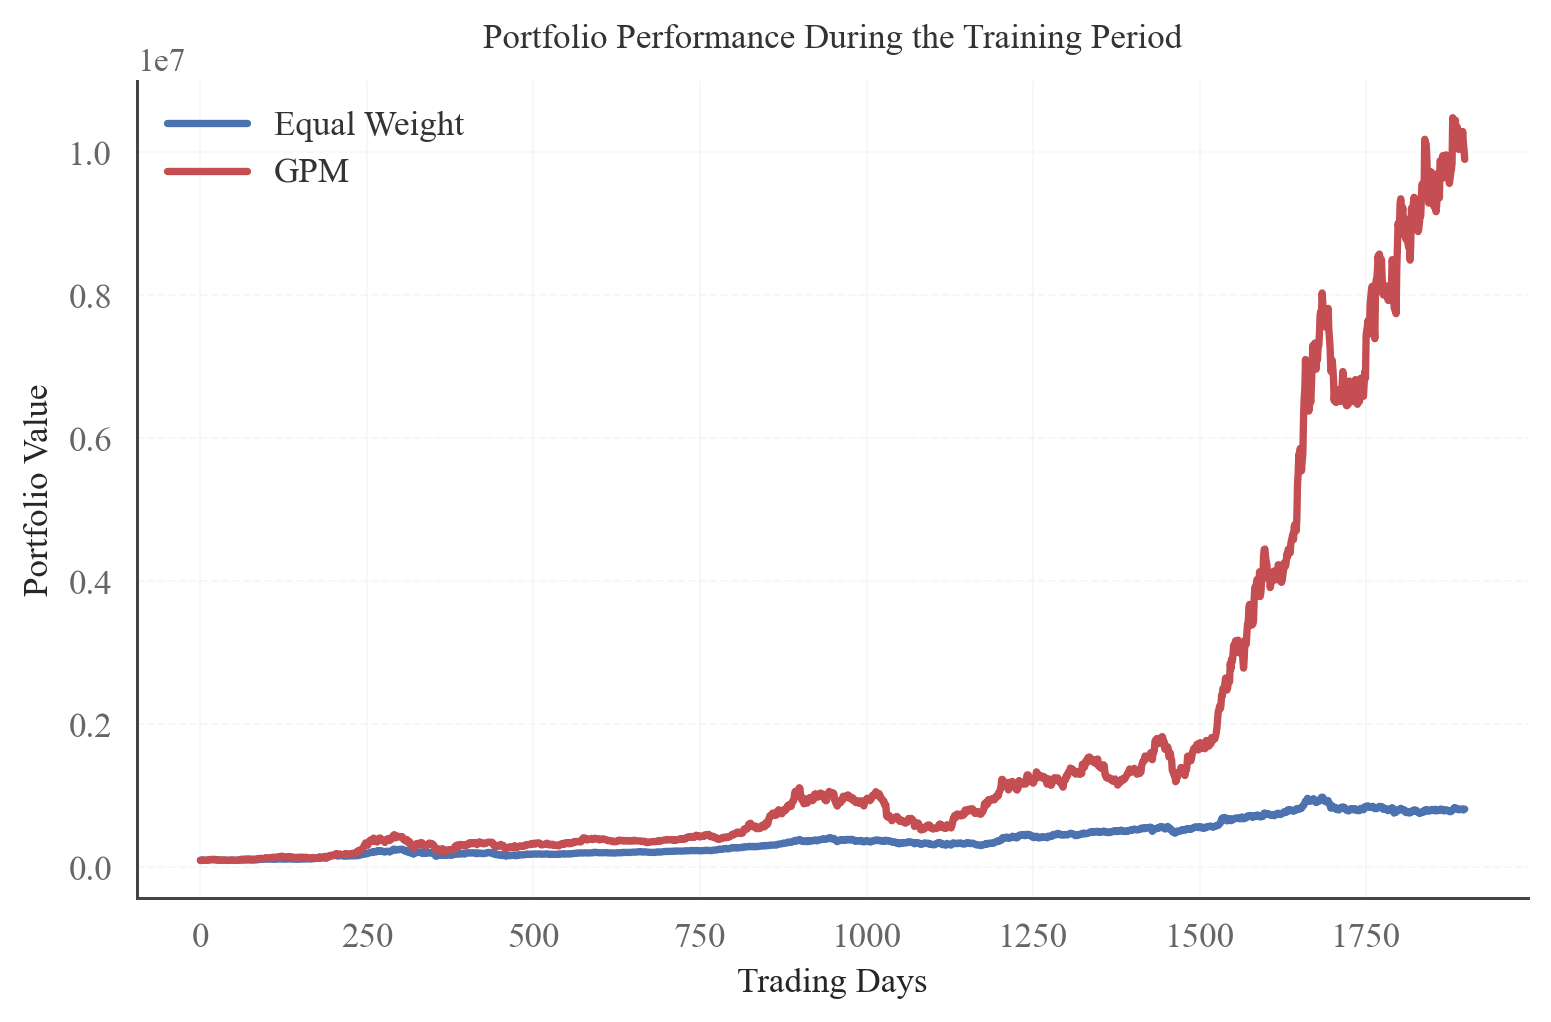

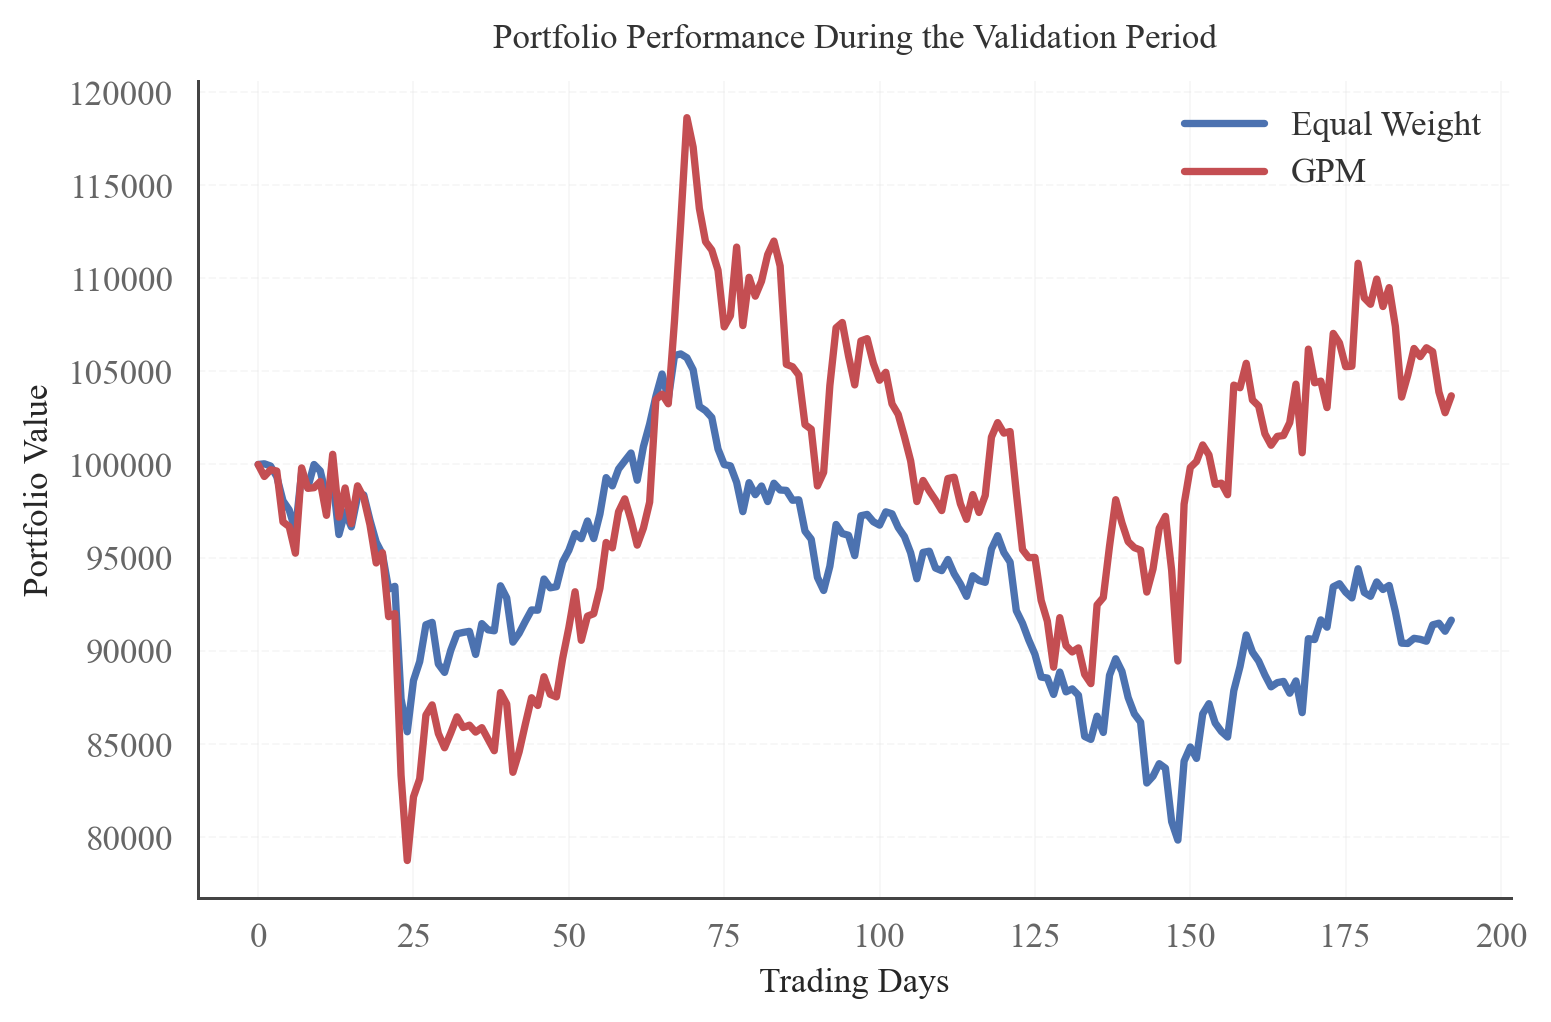

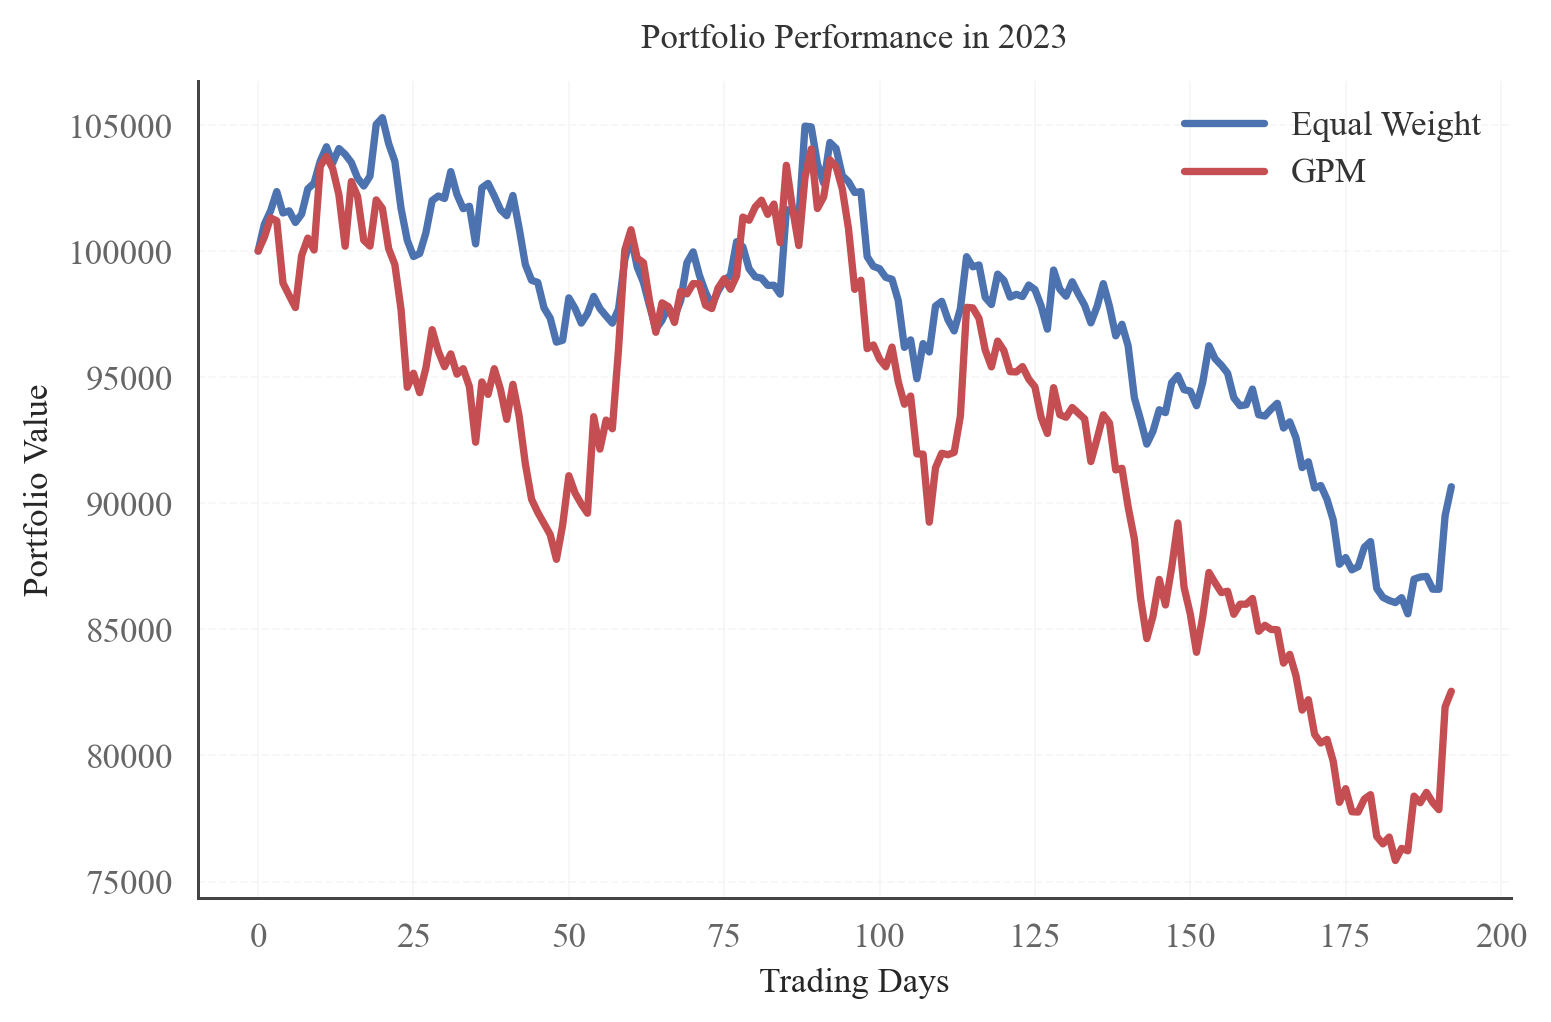

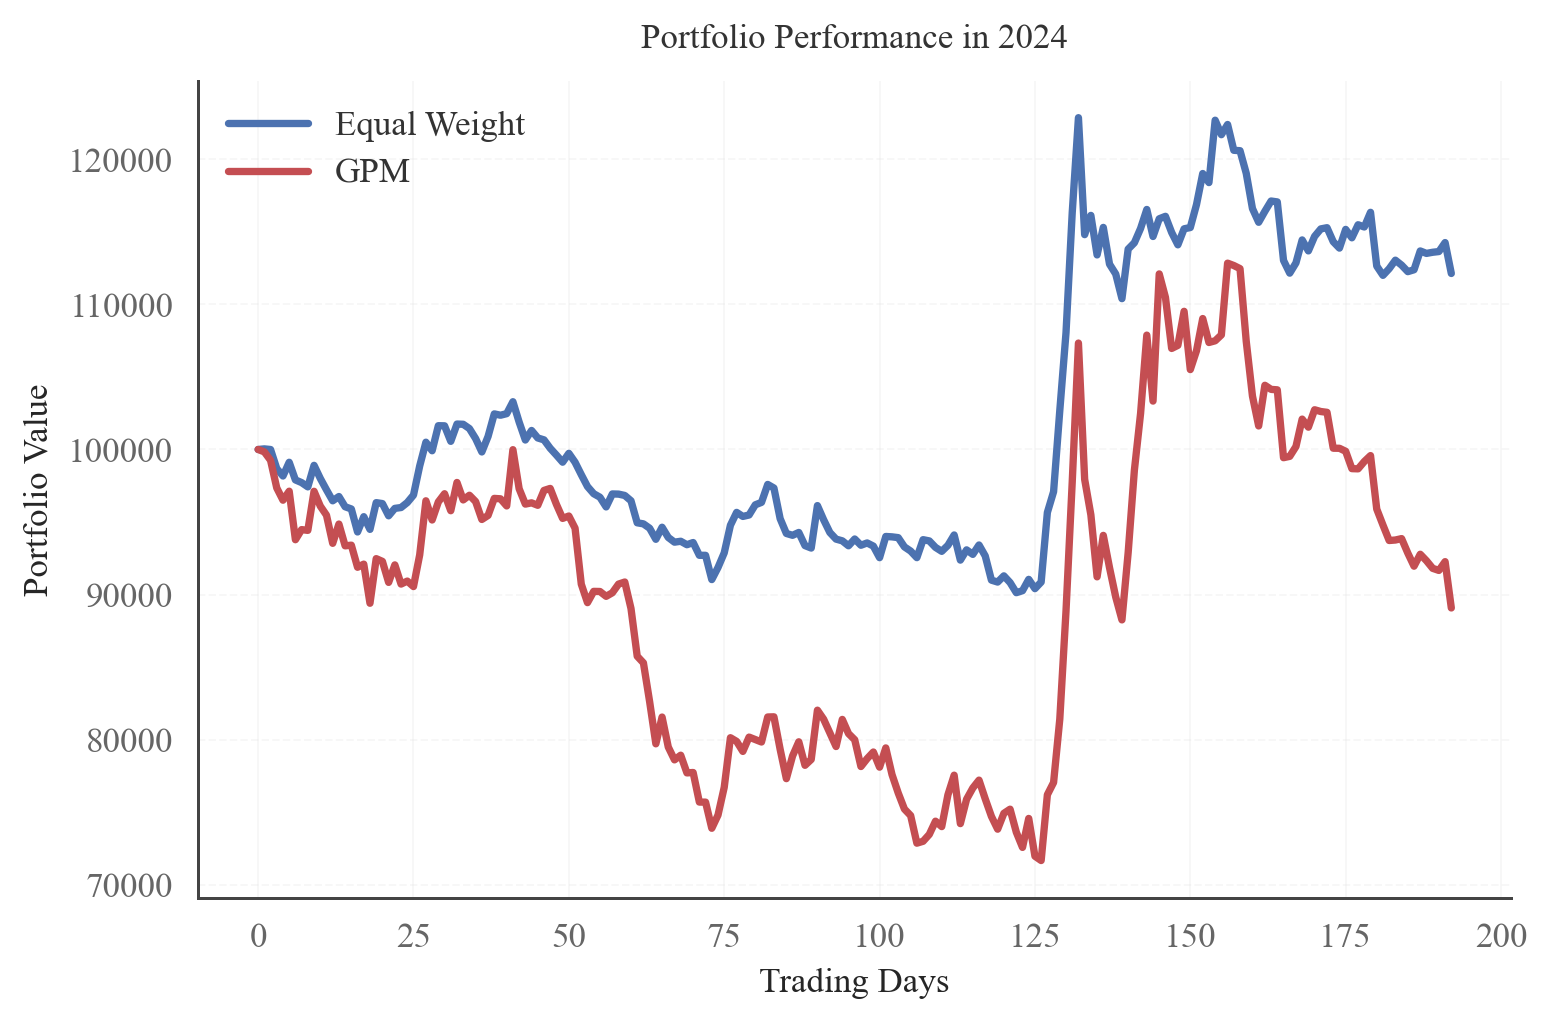

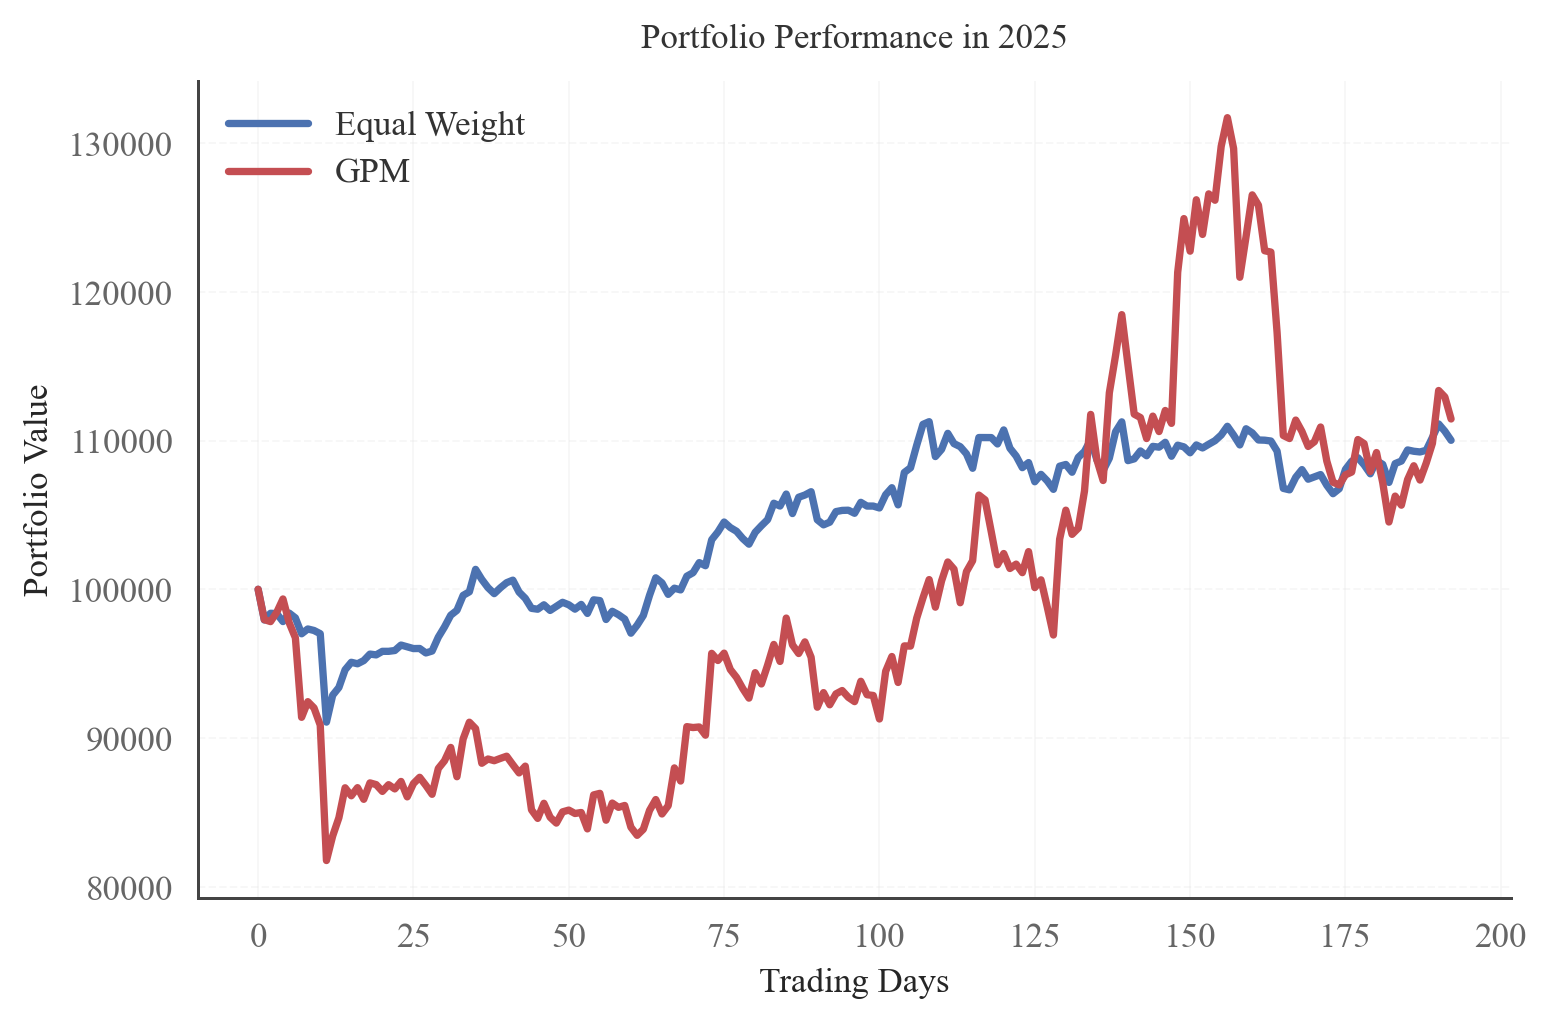

In [57]:
import matplotlib.pyplot as plt
%matplotlib inline 
import os

output_dir = "raw_GPM_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

# Publication-style settings
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "mathtext.fontset": "stix",
    "axes.unicode_minus": False,

    "figure.figsize": (6.6, 4.4),
    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,

    "lines.linewidth": 2.2,
    "axes.linewidth": 0.9,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "legend.frameon": False,
    "legend.handlelength": 2.4,

    "grid.alpha": 0.22,
    "grid.linewidth": 0.6,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# Academic-style muted palette
COLOR_EW = "#4C72B0"
COLOR_GPM = "#C44E52"

def plot_portfolio_value(ew_values, gpm_values, title, save_name=None):
    fig, ax = plt.subplots()

    x_ew = np.arange(len(ew_values))
    x_gpm = np.arange(len(gpm_values))

    ax.plot(
        x_ew,
        ew_values,
        label="Equal Weight",
        color=COLOR_EW,
        linewidth=2.2
    )
    ax.plot(
        x_gpm,
        gpm_values,
        label="GPM",
        color=COLOR_GPM,
        linewidth=2.2
    )

    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Portfolio Value")
    ax.set_title(title, pad=10)

    ax.grid(True, axis="y", linestyle="--")
    ax.legend(loc="best")

    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=4, width=0.8, color="#444444")

    apply_times_new_roman(ax)
    plt.tight_layout()

    if save_name is not None:
        fig.savefig(os.path.join(output_dir, f"{save_name}.png"), bbox_inches="tight")

    plt.show()


plot_portfolio_value(
    EW_results["train"]["value"],
    GPM_results["training"],
    title="Portfolio Performance During the Training Period",
    save_name="value_train"
)

plot_portfolio_value(
    EW_results["validation"]["value"],
    GPM_results["validation"]["value"],
    title="Portfolio Performance During the Validation Period",
    save_name="value_validation"
)

plot_portfolio_value(
    EW_results["2023"]["value"],
    GPM_results["2023"]["value"],
    title="Portfolio Performance in 2023",
    save_name="value_2023"
)

plot_portfolio_value(
    EW_results["2024"]["value"],
    GPM_results["2024"]["value"],
    title="Portfolio Performance in 2024",
    save_name="value_2024"
)

plot_portfolio_value(
    EW_results["2025"]["value"],
    GPM_results["2025"]["value"],
    title="Portfolio Performance in 2025",
    save_name="value_2025"
)


We can see that the agent is able to learn a good policy but its performance is worse the more the test period advances into the future. To get a better performance in 2022, for example, the agent should probably be trained again using more recent data.

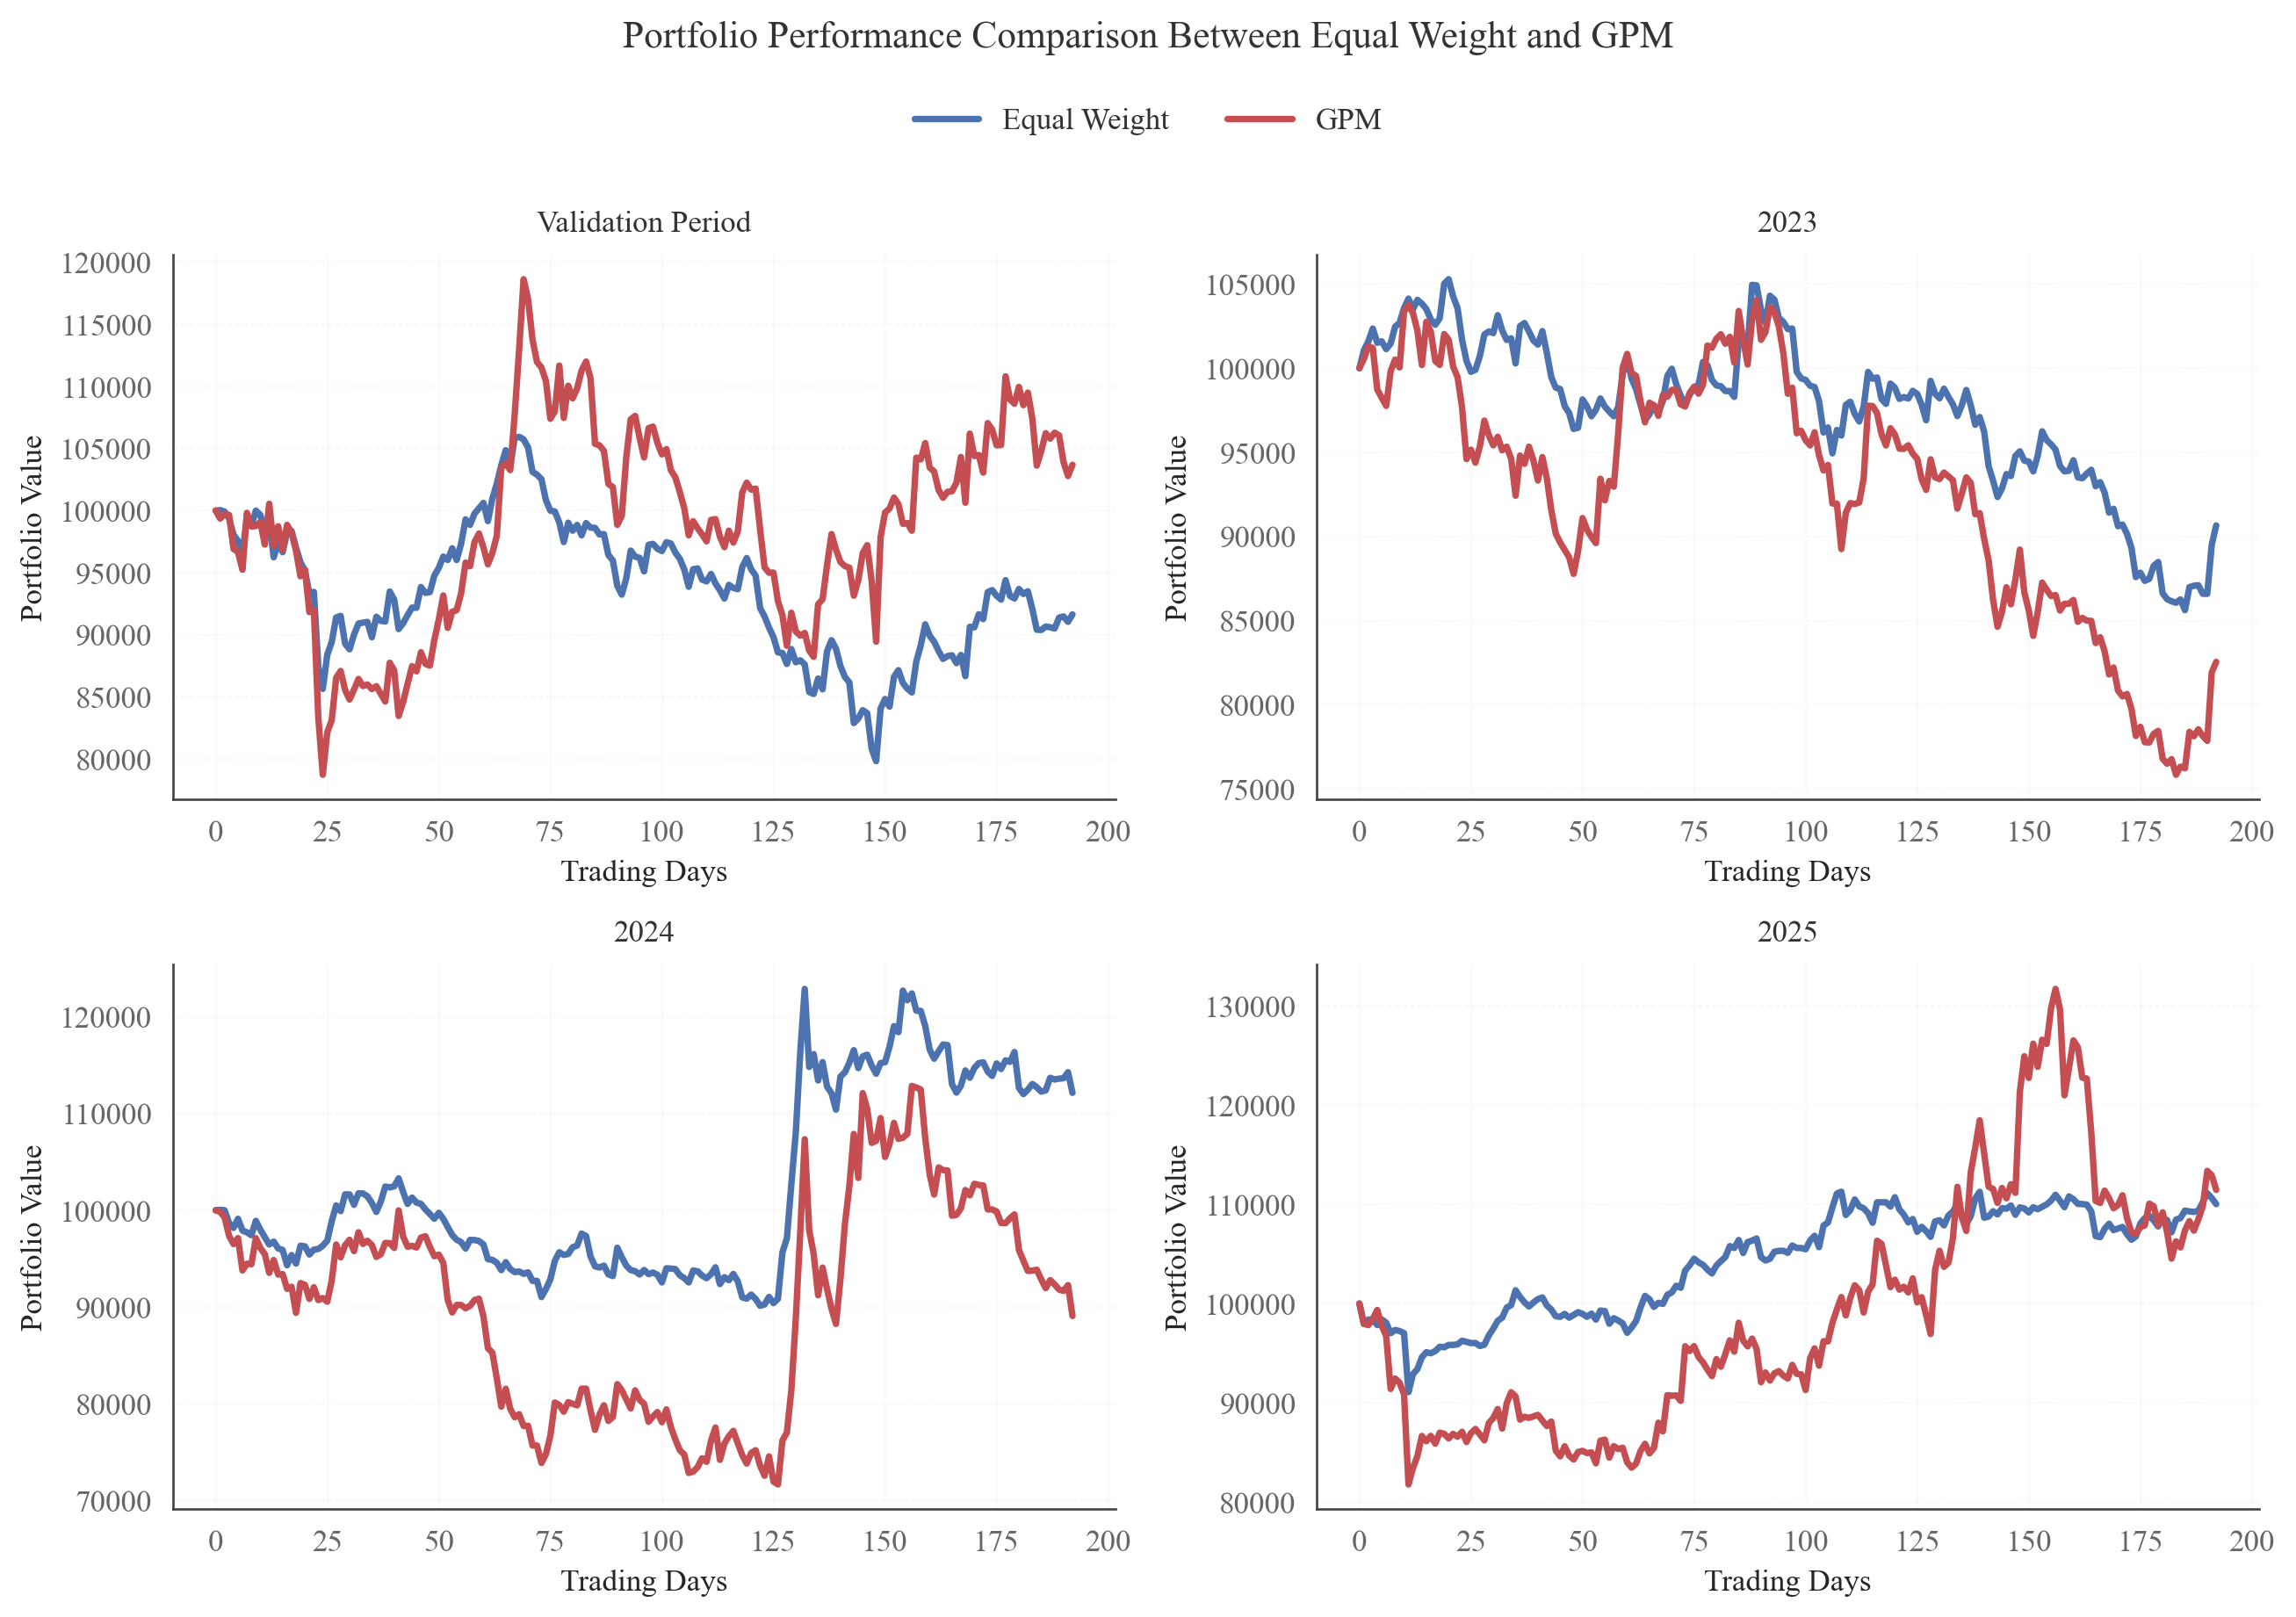

In [58]:
import os
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

output_dir = "raw_GPM_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

# Publication-style settings
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 10,
    "axes.labelsize": 11,
    "axes.titlesize": 11,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 10,

    "lines.linewidth": 2.2,
    "axes.linewidth": 0.8,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "legend.frameon": False,
    "legend.handlelength": 2.2,

    "grid.alpha": 0.20,
    "grid.linewidth": 0.5,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLOR_EW = "#4C72B0"
COLOR_GPM = "#C44E52"

period_data = [
    ("Validation Period", EW_results["validation"]["value"], GPM_results["validation"]["value"]),
    ("2023", EW_results["2023"]["value"], GPM_results["2023"]["value"]),
    ("2024", EW_results["2024"]["value"], GPM_results["2024"]["value"]),
    ("2025", EW_results["2025"]["value"], GPM_results["2025"]["value"]),
]

fig, axes = plt.subplots(2, 2, figsize=(11.0, 7.2))
axes = axes.flatten()

for ax, (title, ew_values, gpm_values) in zip(axes, period_data):
    x_ew = np.arange(len(ew_values))
    x_gpm = np.arange(len(gpm_values))

    ax.plot(x_ew, ew_values, color=COLOR_EW, label="Equal Weight")
    ax.plot(x_gpm, gpm_values, color=COLOR_GPM, label="GPM")

    ax.set_title(title, pad=8)
    ax.set_xlabel("Trading Days")
    ax.set_ylabel("Portfolio Value")

    ax.grid(True, axis="y", linestyle="--")
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

# Shared legend at the top
handles, labels = axes[0].get_legend_handles_labels()
fig_legend = fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.02),
    frameon=False
)
apply_times_new_roman_to_legend(fig_legend)

fig.suptitle("Portfolio Performance Comparison Between Equal Weight and GPM", fontsize=13, y=1.06, fontproperties=TNR_FONT)
for ax in axes:
    apply_times_new_roman(ax)
fig.tight_layout()

fig.savefig(os.path.join(output_dir, "portfolio_performance_comparison.png"), bbox_inches="tight")

plt.show()


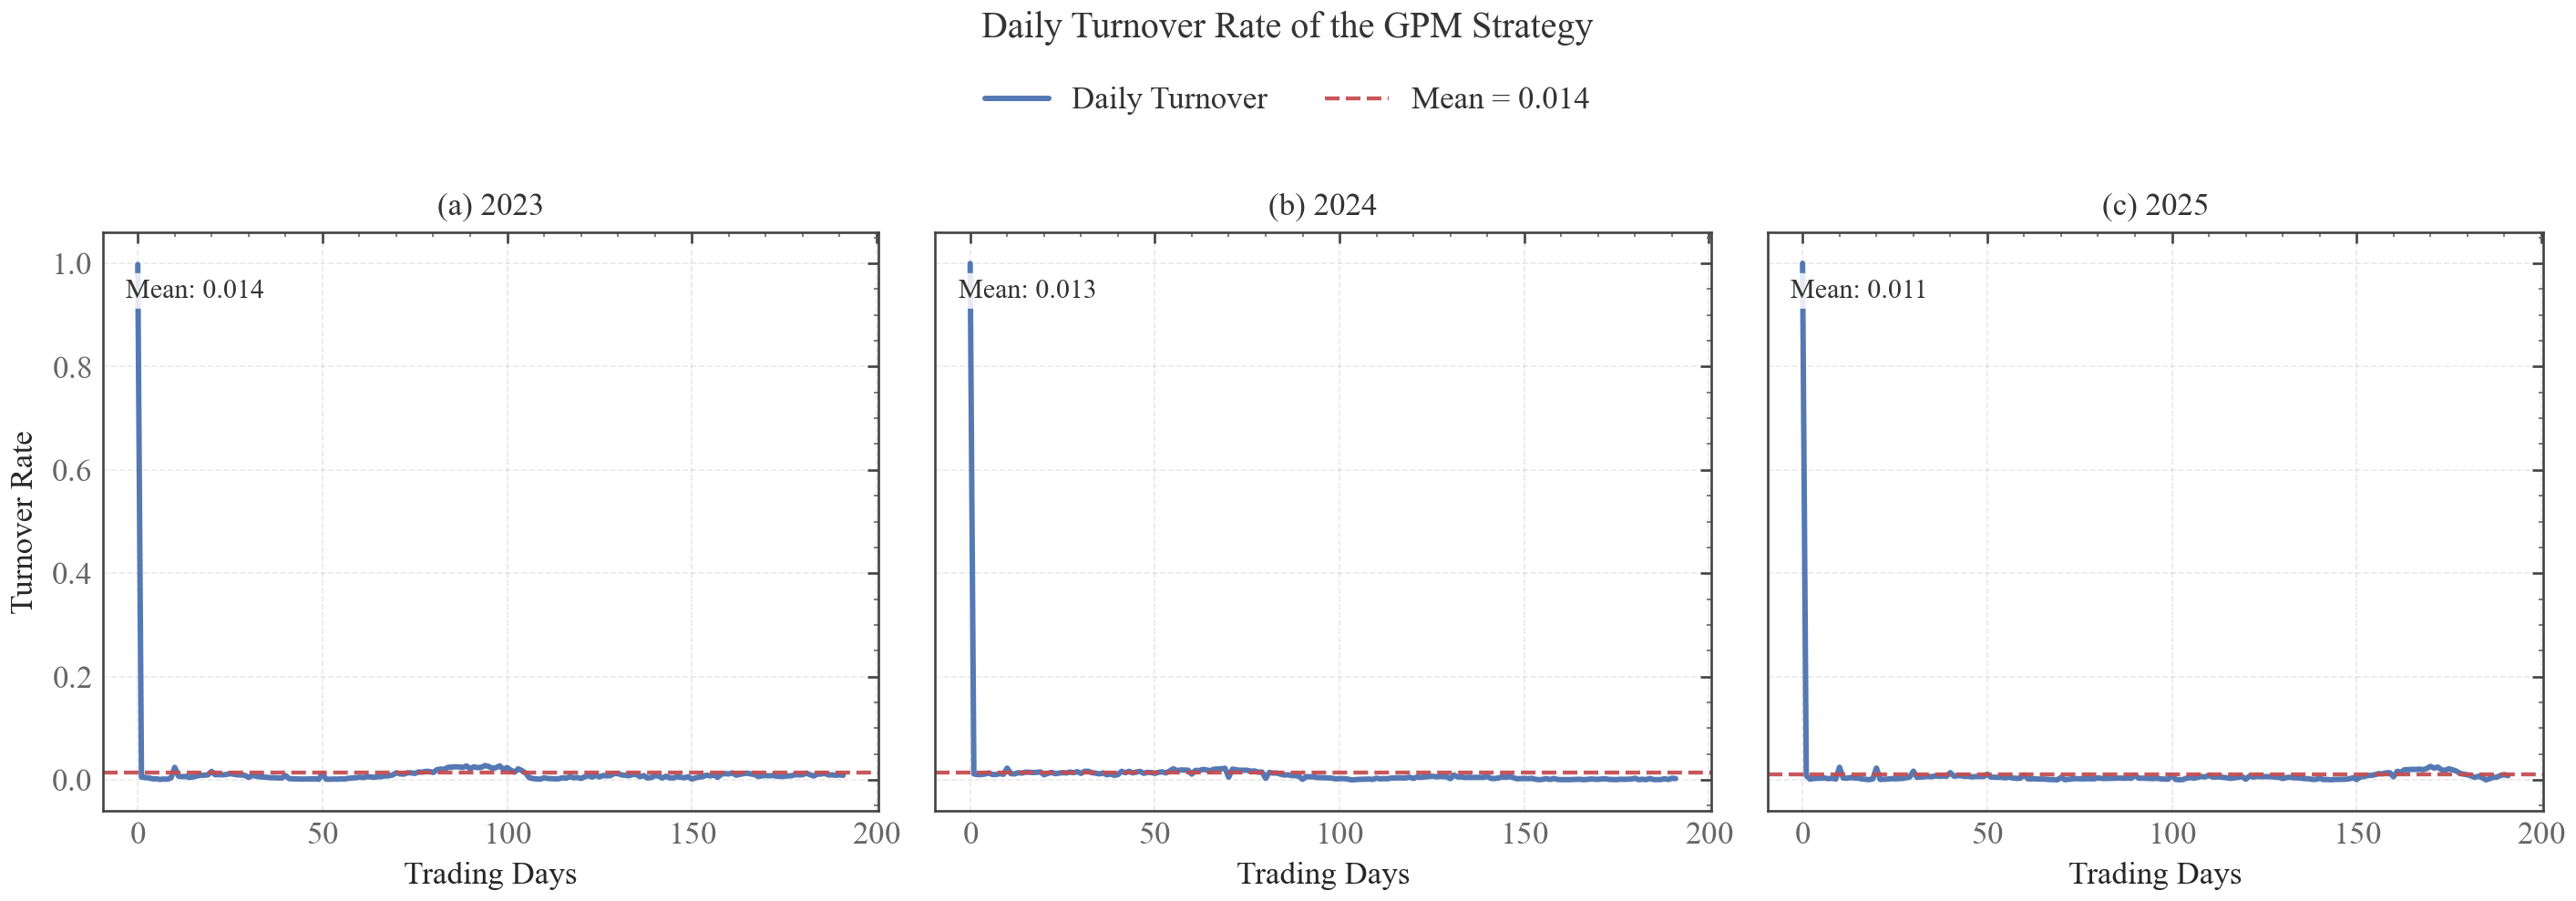

In [59]:
%config InlineBackend.figure_format = "retina"

import os
import numpy as np
import matplotlib.pyplot as plt
import scienceplots

output_dir = "raw_GPM_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

with plt.style.context(["science", "no-latex"]):
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
        "axes.unicode_minus": False,

        "axes.titlesize": 11,
        "axes.labelsize": 11,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 9.5,
        "legend.fontsize": 9.5,

        "axes.linewidth": 0.9,
        "grid.linewidth": 0.5,
        "grid.alpha": 0.28,
        "lines.linewidth": 1.8,

        "savefig.dpi": 400,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    years = ["2023", "2024", "2025"]
    panel_labels = ["(a)", "(b)", "(c)"]

    fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.8), sharey=True)

    line_color = "#4C72B0"
    mean_color = "#C44E52"

    all_turnover = []
    for year in years:
        all_turnover.extend(GPM_results[year]["turnover"])

    y_min = min(all_turnover)
    y_max = max(all_turnover)
    y_margin = 0.06 * (y_max - y_min) if y_max > y_min else 0.02

    for ax, year, panel in zip(axes, years, panel_labels):
        turnover = np.asarray(GPM_results[year]["turnover"])
        days = np.arange(len(turnover))
        mean_turnover = turnover.mean()

        ax.plot(
            days,
            turnover,
            color=line_color,
            linewidth=1.8,
            alpha=0.95,
            label="Daily Turnover"
        )

        ax.axhline(
            mean_turnover,
            linestyle="--",
            linewidth=1.3,
            color=mean_color,
            alpha=0.95,
            label=f"Mean = {mean_turnover:.3f}"
        )

        ax.set_title(f"{panel} {year}", pad=6)
        ax.set_xlabel("Trading Days")
        ax.set_ylim(y_min - y_margin, y_max + y_margin)

        if ax is axes[0]:
            ax.set_ylabel("Turnover Rate")

        ax.grid(True, linestyle="--", color="#B0B0B0")
        ax.set_axisbelow(True)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(0.8)
            spine.set_color("#444444")

        ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

        ax.text(
            0.03, 0.92,
            f"Mean: {mean_turnover:.3f}",
            transform=ax.transAxes,
            fontsize=9,
            ha="left",
            va="top",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="none",
                alpha=0.85
            )
        )

    handles, labels = axes[0].get_legend_handles_labels()
    fig_legend = fig.legend(
        handles,
        labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 1.04),
        ncol=2,
        frameon=False
    )
    apply_times_new_roman_to_legend(fig_legend)

    fig.suptitle("Daily Turnover Rate of the GPM Strategy", fontsize=12, y=1.10, fontproperties=TNR_FONT)
    for ax in axes:
        apply_times_new_roman(ax)
    fig.tight_layout()

    fig.savefig(os.path.join(output_dir, "turnover_comparison.png"), bbox_inches="tight")

    plt.show()


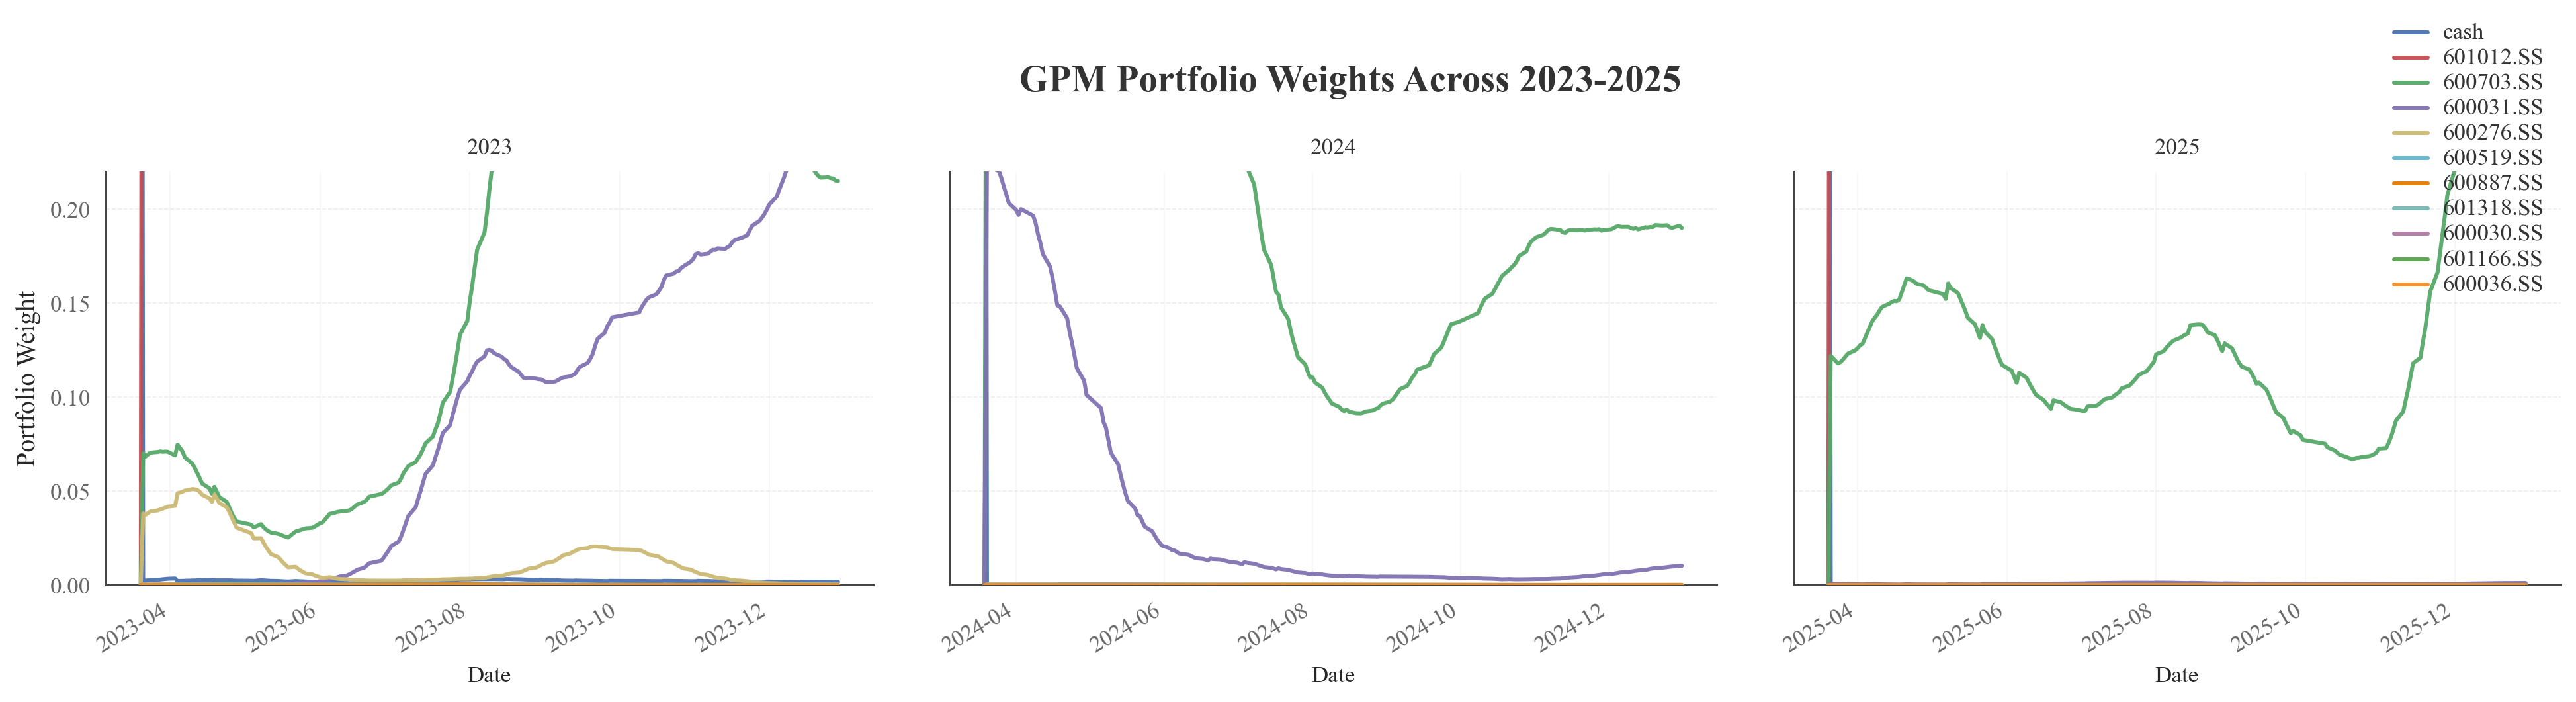

In [60]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%config InlineBackend.figure_format = "retina"

output_dir = "raw_GPM_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 14,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 8.5,

    "axes.linewidth": 0.9,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.22,
    "lines.linewidth": 1.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

HIGHLIGHT_COLORS = [
    "#4C72B0", "#C44E52", "#55A868", "#8172B2", "#CCB974",
    "#64B5CD", "#E17C05", "#76B7B2", "#B07AA1", "#59A14F",
    "#F28E2B", "#8C8C8C"
]

def _prepare_action_plot_data(actions, raw_df, top_k=11, highlight_cash=True):
    actions = np.asarray(actions, dtype=np.float32)

    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = pd.to_datetime(dates[-n_steps:]) if len(dates) >= n_steps else np.arange(n_steps)

    tics = sorted(raw_df["tic"].unique().tolist())
    if actions.shape[1] == len(tics) + 1:
        labels = ["cash"] + tics
    else:
        labels = [f"asset_{i}" for i in range(actions.shape[1])]

    avg_weights = actions.mean(axis=0)
    sorted_idx = np.argsort(avg_weights)[::-1]

    if highlight_cash and labels[0] == "cash":
        cash_idx = 0
        stock_idx = [i for i in sorted_idx if i != cash_idx]
        highlight_idx = [cash_idx] + stock_idx[:top_k]
    else:
        highlight_idx = sorted_idx[:top_k]

    return actions, x_dates, labels, highlight_idx

def plot_actions_triptych(
    result_dict,
    raw_df_dict,
    years=("2023", "2024", "2025"),
    save_path=None,
    top_k=11,
    y_max=0.22,
):
    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.2), sharey=True)

    for ax, year in zip(axes, years):
        actions, x_dates, labels, highlight_idx = _prepare_action_plot_data(
            result_dict[year]["actions"],
            raw_df_dict[year],
            top_k=top_k,
            highlight_cash=True
        )

        # background assets
        for i in range(actions.shape[1]):
            if i in highlight_idx:
                continue
            ax.plot(
                x_dates,
                actions[:, i],
                color="#C8C8C8",
                linewidth=0.7,
                alpha=0.16,
                zorder=1
            )

        # highlighted assets
        for j, i in enumerate(highlight_idx):
            ax.plot(
                x_dates,
                actions[:, i],
                color=HIGHLIGHT_COLORS[j % len(HIGHLIGHT_COLORS)],
                linewidth=1.8,
                alpha=0.95,
                label=labels[i],
                zorder=3
            )

        ax.set_title(year, pad=8, fontsize=15)
        ax.set_xlabel("Date")
        ax.set_ylim(0.0, y_max)

        ax.grid(True, axis="y", linestyle="--", color="#B0B0B0")
        ax.set_axisbelow(True)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#444444")
        ax.spines["bottom"].set_color("#444444")
        ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

        ax.set_yticks(np.arange(0.0, y_max + 1e-9, 0.05))

        if ax is axes[-1]:
            ax.legend(
                loc="upper right",
                bbox_to_anchor=(1.00, 1.4),
                ncol=1,
                frameon=False,
                labelspacing=0.25,
                handlelength=1.8
            )
        apply_times_new_roman(ax)

    axes[0].set_ylabel("Portfolio Weight", fontsize=12)

    fig.suptitle(
        "GPM Portfolio Weights Across 2023-2025",
        fontsize=17,
        x=0.53,
        y=0.98,
        fontweight="semibold",
        fontproperties=TNR_FONT
    )

    # Compress whitespace
    fig.subplots_adjust(
        left=0.055,
        right=0.992,
        bottom=0.20,
        top=0.82,
        wspace=0.10
    )

    fig.savefig(save_path, bbox_inches="tight")

    plt.show()


plot_actions_triptych(
    result_dict=GPM_results,
    raw_df_dict={
        "2023": df_portfolio_2023,
        "2024": df_portfolio_2024,
        "2025": df_portfolio_2025,
    },
    years=("2023", "2024", "2025"),
    save_path=os.path.join(output_dir, "GPM_weights_triptych.png"),
    top_k=11,
    y_max=0.22
)


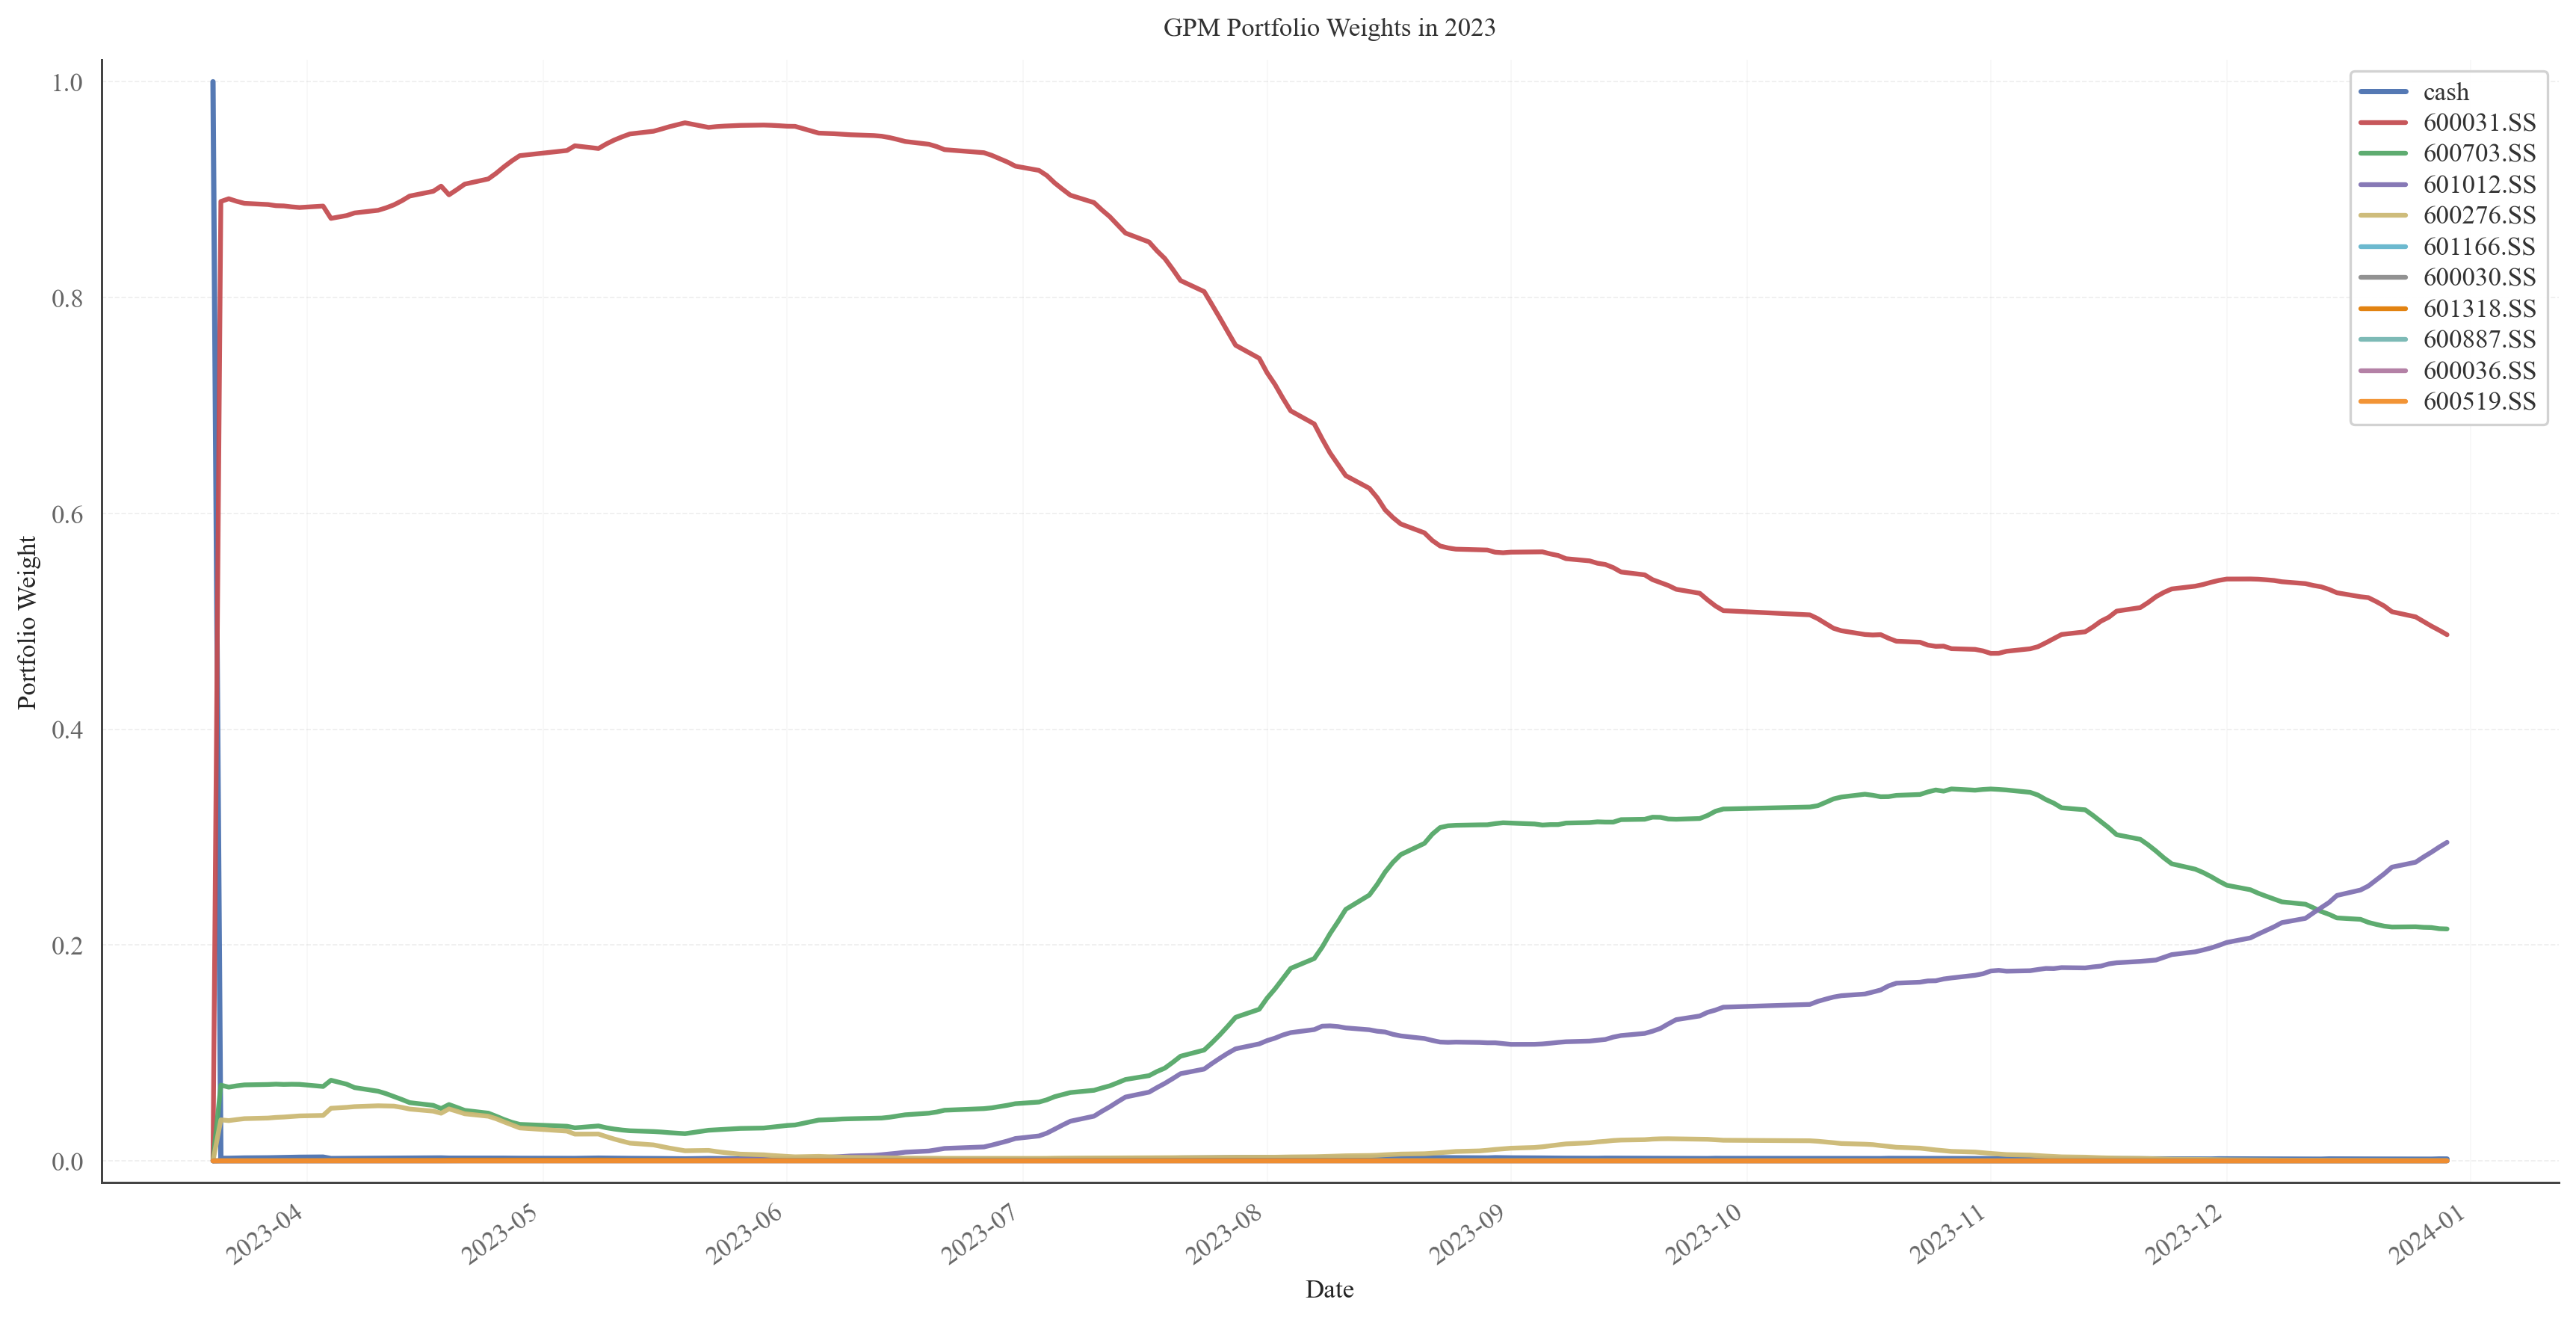

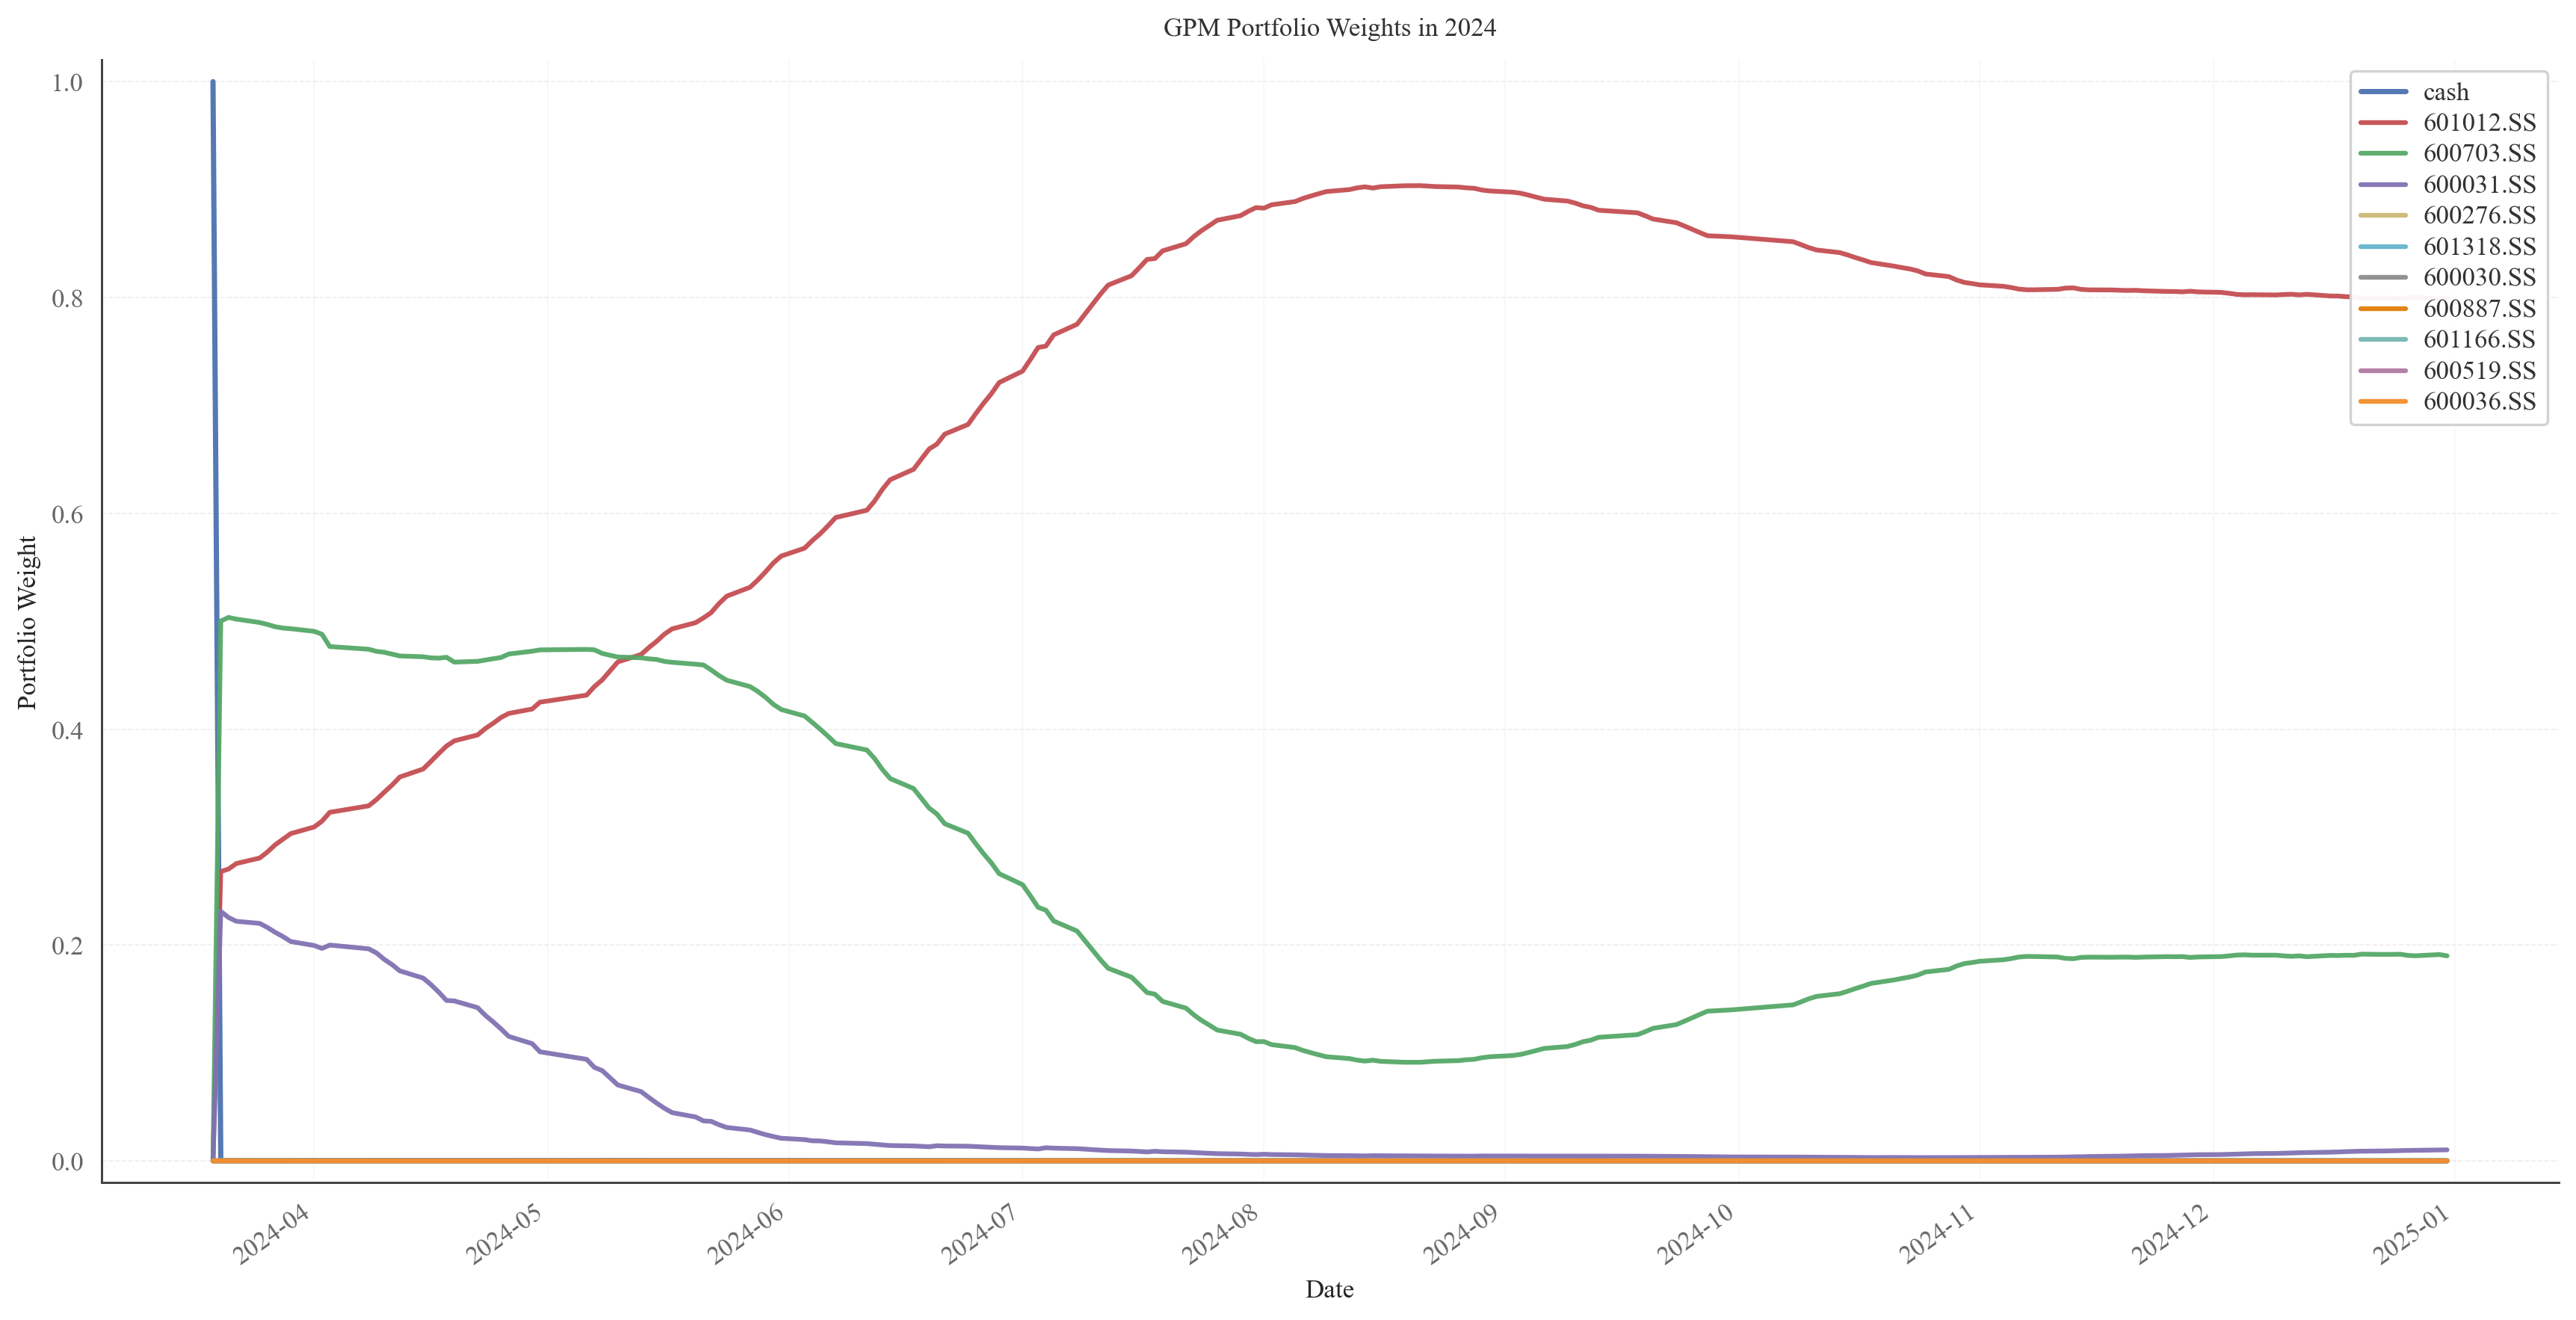

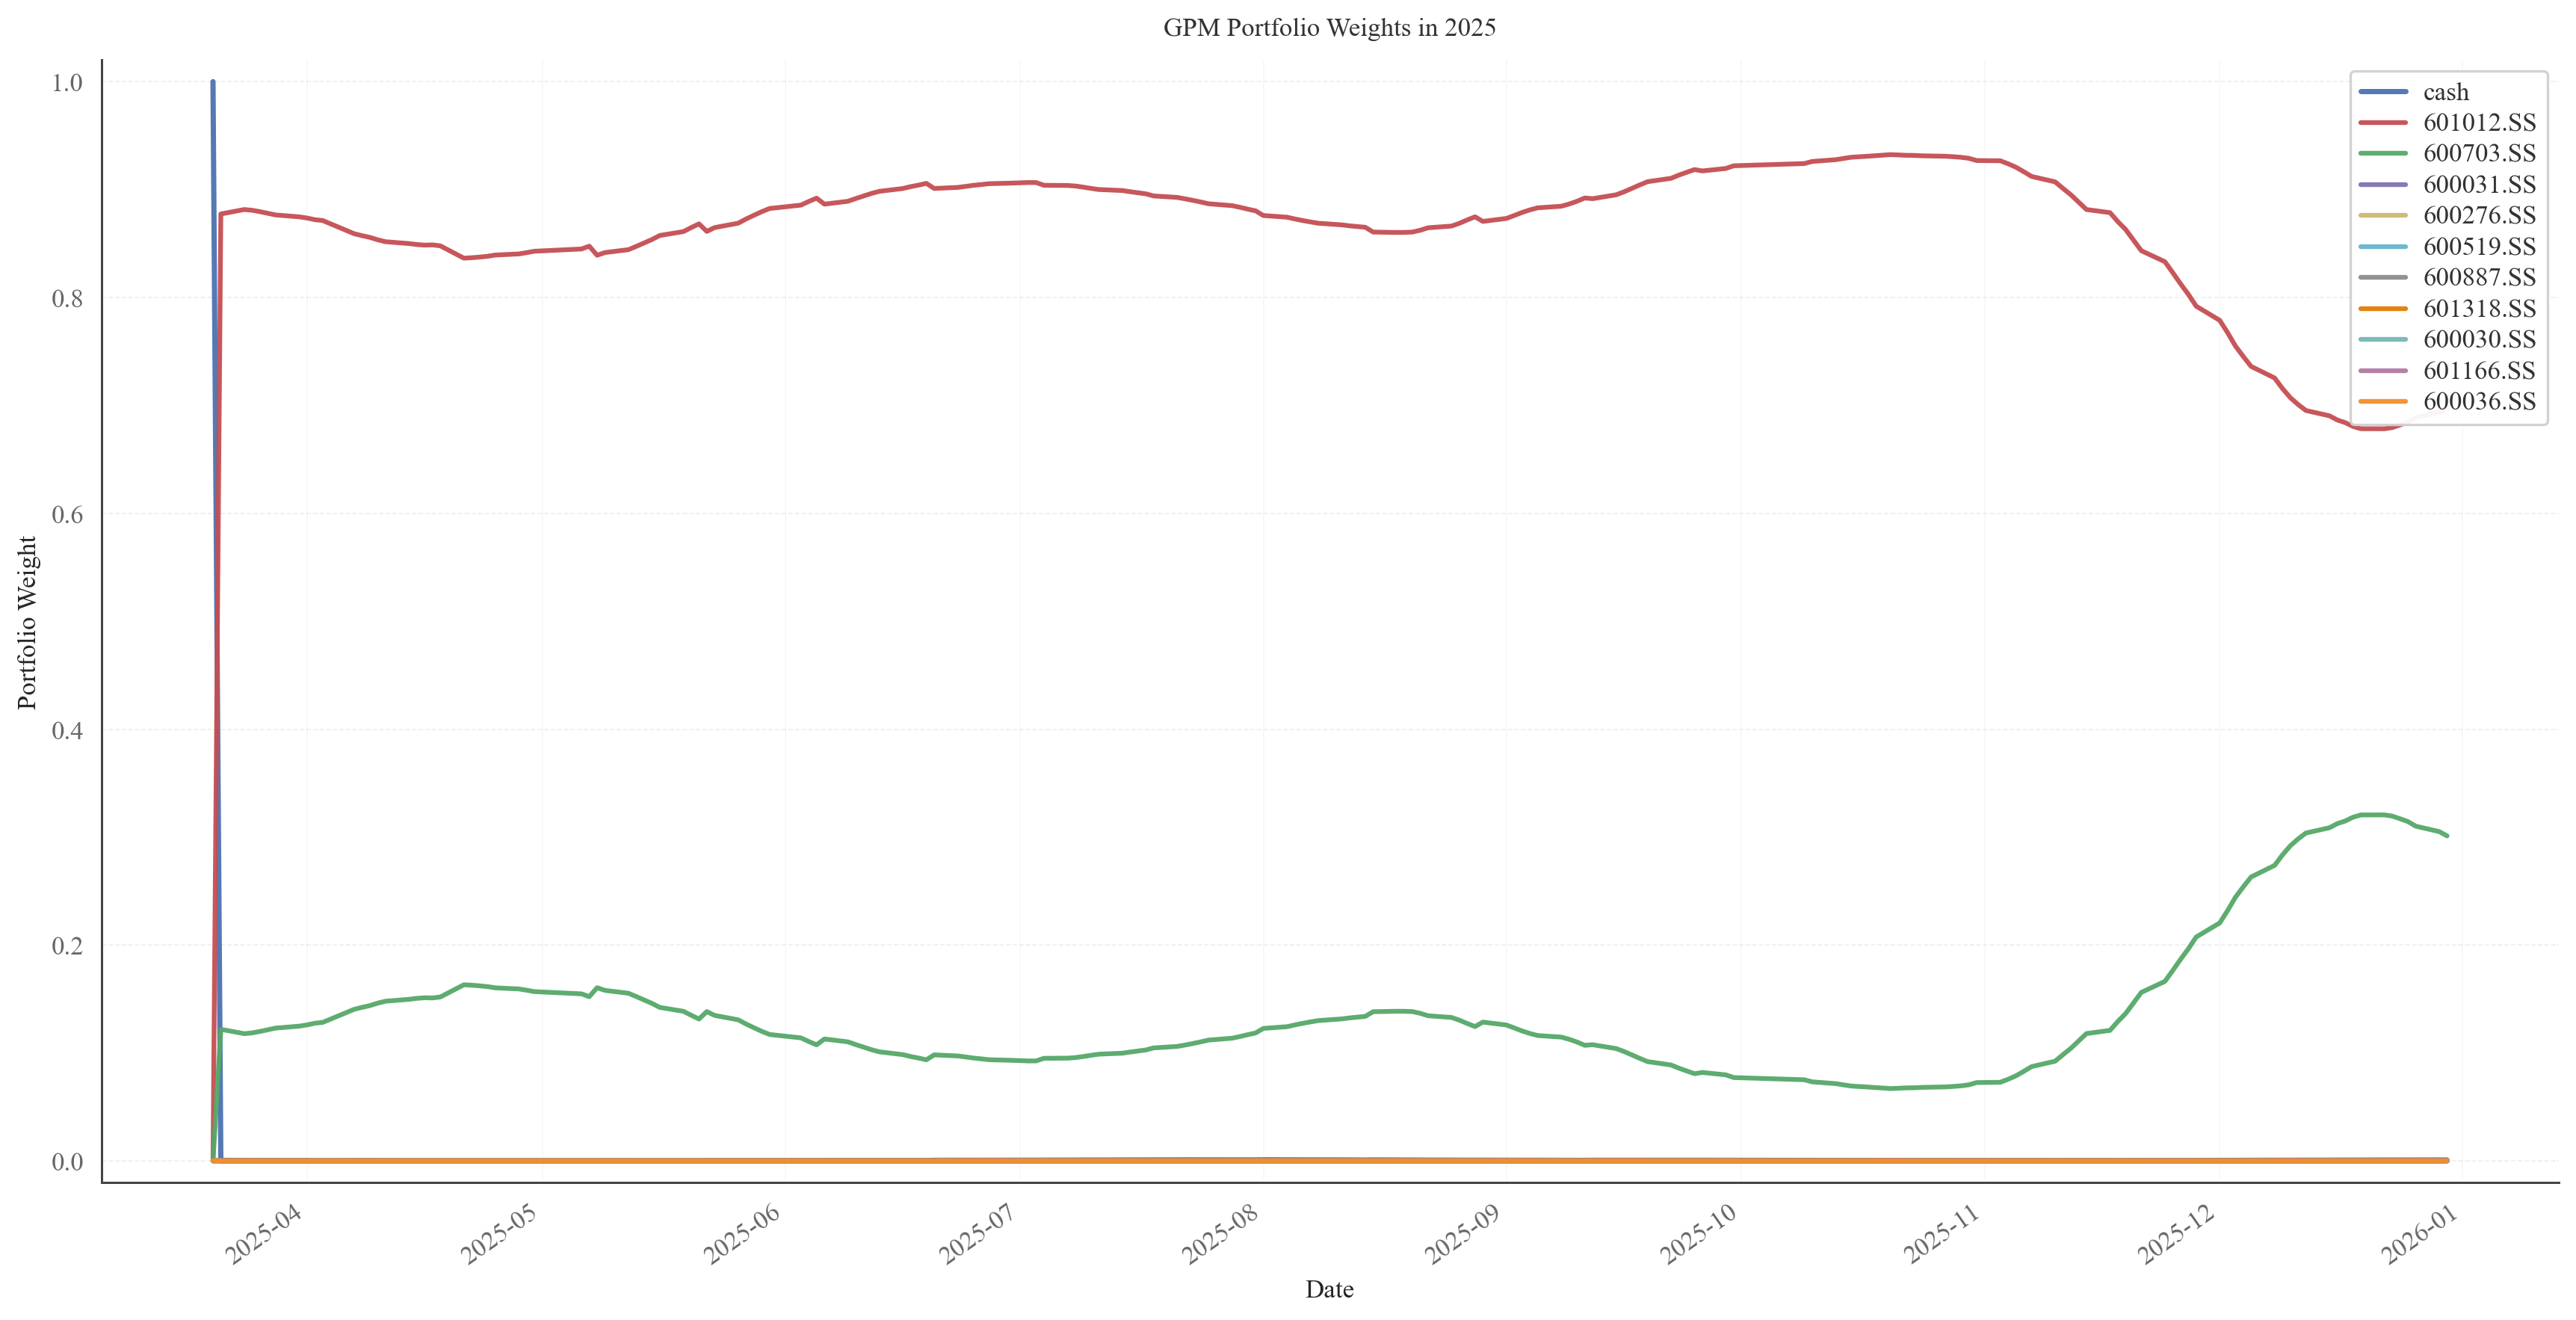

In [61]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

%config InlineBackend.figure_format = "retina"

output_dir = "raw_GPM_sse50_figures"
os.makedirs(output_dir, exist_ok=True)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.sans-serif": ["SimSun", "Songti SC", "STSong", "SimHei", "Microsoft YaHei", "DejaVu Sans"],
    "axes.unicode_minus": False,

    "figure.dpi": 120,
    "savefig.dpi": 400,

    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9,

    "axes.linewidth": 0.9,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.22,
    "lines.linewidth": 1.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# A restrained academic palette for highlighted assets
HIGHLIGHT_COLORS = [
    "#4C72B0", "#C44E52", "#55A868", "#8172B2", "#CCB974",
    "#64B5CD", "#8C8C8C", "#E17C05", "#76B7B2", "#B07AA1",
    "#F28E2B", "#59A14F"
]

def plot_actions_pretty(
    actions,
    raw_df,
    title,
    save_path=None,
    top_k=11,
    figsize=(14.5, 7.5),
    highlight_cash=True,
):
    actions = np.asarray(actions, dtype=np.float32)

    # 1. Build the date axis
    dates = sorted(pd.to_datetime(raw_df["date"]).unique())
    n_steps = actions.shape[0]
    x_dates = pd.to_datetime(dates[-n_steps:]) if len(dates) >= n_steps else np.arange(n_steps)

    # 2. Build labels
    tics = sorted(raw_df["tic"].unique().tolist())
    if actions.shape[1] == len(tics) + 1:
        labels = ["cash"] + tics
    else:
        labels = [f"asset_{i}" for i in range(actions.shape[1])]

    # 3. Select highlighted assets based on average allocation
    avg_weights = actions.mean(axis=0)
    sorted_idx = np.argsort(avg_weights)[::-1]

    if highlight_cash and labels[0] == "cash":
        cash_idx = 0
        stock_idx = [i for i in sorted_idx if i != cash_idx]
        highlight_idx = [cash_idx] + stock_idx[:top_k]
    else:
        cash_idx = None
        highlight_idx = sorted_idx[:top_k]

    fig, ax = plt.subplots(figsize=figsize)

    # 4. Plot non-highlighted assets in the background
    for i in range(actions.shape[1]):
        if i in highlight_idx:
            continue
        ax.plot(
            x_dates,
            actions[:, i],
            color="#B8B8B8",
            linewidth=0.8,
            alpha=0.18,
            zorder=1
        )

    # 5. Plot highlighted assets, including cash in the same style family
    for j, i in enumerate(highlight_idx):
        color = HIGHLIGHT_COLORS[j % len(HIGHLIGHT_COLORS)]
        ax.plot(
            x_dates,
            actions[:, i],
            color=color,
            linewidth=1.9 if labels[i] != "cash" else 2.1,
            alpha=0.95,
            label=labels[i],
            zorder=3
        )

    # 6. Axes styling
    ax.set_title(title, pad=10)
    ax.set_xlabel("Date")
    ax.set_ylabel("Portfolio Weight")
    ax.set_ylim(-0.02, 1.02)

    ax.grid(True, axis="y", linestyle="--", color="#B0B0B0")
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#444444")
    ax.spines["bottom"].set_color("#444444")
    ax.tick_params(axis="both", which="major", length=3.5, width=0.8, color="#444444")

    # 7. Format the x-axis as year-month, e.g. 2023-01
    if isinstance(x_dates[0], (np.datetime64, pd.Timestamp)):
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
        plt.setp(ax.get_xticklabels(), rotation=35, ha="right")

    # 8. Legend in the upper-right corner
    ax.legend(
        loc="upper right",
        ncol=1,
        frameon=True,
        framealpha=0.95,
        facecolor="white",
        edgecolor="#D0D0D0",
        borderpad=0.45,
        labelspacing=0.35,
        handlelength=2.0
    )

    apply_times_new_roman(ax)
    plt.tight_layout()

    if save_path:
        fig.savefig(save_path, bbox_inches="tight")
        if save_path.lower().endswith(".png"):
            fig.savefig(save_path[:-4] + ".pdf", bbox_inches="tight")

    plt.show()


plot_actions_pretty(
    GPM_results["2023"]["actions"],
    df_portfolio_2023,
    "GPM Portfolio Weights in 2023",
    top_k=11
)

plot_actions_pretty(
    GPM_results["2024"]["actions"],
    df_portfolio_2024,
    "GPM Portfolio Weights in 2024",
    top_k=11
)

plot_actions_pretty(
    GPM_results["2025"]["actions"],
    df_portfolio_2025,
    "GPM Portfolio Weights in 2025",
    top_k=11
)
